# Quantenmessung

Das Notebook baut die Messtheorie von den Messoperatoren bis zur Tomographie auf und simuliert jede Methode mit numpy (das SDP mit cvxpy): POVMs und Naimark-Dilatation, das von-Neumann-Zeigermodell, Zustandsunterscheidung (Helstrom, eindeutige Unterscheidung, Pretty-Good-Measurement, SDP), Unschärfe und gemeinsame Messbarkeit, schwache Messung und Weak Values, kontinuierliche Messung mit Quanten-Trajektorien (Diffusion und Sprünge), Zeno-Effekt und Feedback, Zustands- und Prozesstomographie, Randomized Benchmarking und Classical Shadows.

Welche Arten von Messung erlaubt die Quantenmechanik, was kostet jede Messung an Störung des Zustands, und was kann man mit ihnen über einen unbekannten Zustand oder Prozess herausfinden?

#### **Hintergrund**

Die projektive Messung mit Born- und Lüders-Regel ist im Notebook [Projektive Messung und Born-Regel](https://github.com/deltorobarba/science/blob/main/quantum/bornrule.ipynb) aus dem Spektralsatz hergeleitet. Dieses Notebook verallgemeinert sie in vier Schritten: (1) welche mathematischen Objekte eine Messung beschreiben, (2) was Messungen leisten können und wo ihre Grenzen liegen, (3) schwache und kontinuierliche Messungen, bei denen der Kollaps ein zeitlicher Prozess wird, (4) Messprotokolle, mit denen man Zustände, Kanäle und Gatter charakterisiert. Die Abstandsmaße (Spurabstand, Fidelity), mit denen die Fehler hier gemessen werden, stehen im Notebook [Quanteninformationstheorie und Abstandsmaße](https://github.com/deltorobarba/science/blob/main/quantum/quantuminformation.ipynb).

Landkarte:

- **Grundformen**
  - Projektive Messung (PVM): wiederholbare Messung einer Observablen, $p(k) = \mathrm{Tr}(\rho P_k)$ (Notebook Born-Regel).
  - Messoperatoren und Quanteninstrument: Statistik **und** Zustand danach, $p(m) = \mathrm{Tr}(M_m\rho M_m^\dagger)$ (Theorie 1).
  - POVM und Naimark-Dilatation (Exp. 1): mehr Ergebnisse als die Dimension; jedes POVM ist projektiv auf einem größeren Raum.
  - Von-Neumann-Zeigermodell (Exp. 2): Messung als Wechselwirkung mit einem Gerät, $U = e^{-igA\otimes\hat p}$.
- **Leistung und Grenzen**
  - Information gegen Störung (Exp. 2): Jede Information kostet Kohärenz, $\Phi(g/\sigma)$ gegen $e^{-g^2/2\sigma^2}$.
  - Helstrom-Messung und eindeutige Unterscheidung (Exp. 3): kleinster Fehler für zwei Zustände bzw. nie falsch, dafür manchmal „?“.
  - Pretty-Good-Measurement und SDP (Exp. 4): beste Messung für mehr als zwei Zustände.
  - Unschärferelationen und gemeinsame Messbarkeit (Exp. 5): Robertson, Schrödinger, Maassen–Uffink; $\eta_x^2 + \eta_z^2\le1$.
- **Schwach und kontinuierlich**
  - Schwache Messung und Weak Value (Exp. 6): Mittelwert fast ohne Störung; Postselektion, $A_w = \langle\phi\vert A\vert\psi\rangle/\langle\phi\vert\psi\rangle$.
  - Kontinuierliche Messung (Exp. 7): der Kollaps als Zufallsweg, die Born-Regel als dessen Ausgang.
  - Photodetektion gegen Homodyn-Detektion (Exp. 8): dieselbe Mastergleichung, Sprünge oder Diffusion.
  - Zeno-Effekt und QND-Messung (Exp. 9): häufiges Messen friert die Dynamik ein, $\cos^{2N}(\Omega T/2N)\to1$.
  - Feedback (Exp. 10): Das Messsignal steuert den Zustand, $H_\text{fb} = -\tfrac\lambda2\langle\sigma_x\rangle\sigma_y$.
- **Charakterisierung**
  - Zustandstomographie (Exp. 11): der ganze Zustand aus Pauli-Messungen, lineare Inversion gegen Maximum-Likelihood.
  - Prozesstomographie (Exp. 12): der ganze Kanal als Pauli-Transfermatrix $R_{ij}$.
  - Randomized Benchmarking (Exp. 13): mittlere Gatterfehlerrate, unempfindlich gegen SPAM, $F(m) = Ap^m + B$.
  - Classical Shadows (Exp. 14): viele Erwartungswerte aus zufälligen Einzel-Qubit-Messungen.

Nicht simuliert, aber Teil der Landkarte (Abschnitt „Nächste Schritte“): Gate-Set-Tomographie, Cross-Entropy-Benchmarking, Direct Fidelity Estimation, Korrektur von Auslesefehlern, Bell-Messung und Teleportation, Homodyn- und Heterodyn-Messung kontinuierlicher Variablen, messungsinduzierte Phasenübergänge, Messungen in der Quantenmetrologie.

#### **Theorie**

##### *1. Messoperatoren, POVM, Instrument*

Eine Messung mit den Ergebnissen $m$ wird durch **Messoperatoren** $M_m$ beschrieben, die
$$\sum_mM_m^\dagger M_m = I$$
erfüllen. Im Zustand $\rho$ tritt $m$ mit der Wahrscheinlichkeit $p(m) = \mathrm{Tr}(M_m\rho M_m^\dagger)$ auf, und der Zustand danach ist $\rho_m = M_m\rho M_m^\dagger/p(m)$. Liest man das Ergebnis nicht ab, ist der Zustand danach $\sum_mM_m\rho M_m^\dagger$.

Für die Statistik allein zählen nur die **POVM-Elemente** (Positive Operator-Valued Measure) $E_m = M_m^\dagger M_m$:
$$p(m) = \mathrm{Tr}(E_m\rho),\qquad E_m\geq0,\qquad\sum_mE_m = I .$$
Verschiedene Messoperatoren können dasselbe POVM haben: $M_m = U_m\sqrt{E_m}$ mit beliebigen Unitären $U_m$ liefert dieselben Wahrscheinlichkeiten, aber andere Zustände danach. Die Wahl $M_m = \sqrt{E_m}$ heißt **Lüders-Instrument**. Allgemein heißt eine Familie vollständig positiver Abbildungen $\mathcal I_m$, deren Summe die Spur erhält, ein **Quanteninstrument**: $p(m) = \mathrm{Tr}\,\mathcal I_m(\rho)$, Zustand danach $\mathcal I_m(\rho)/p(m)$.

Projektive Messungen sind der Spezialfall $E_m = P_m$ mit orthogonalen Projektoren. Ein POVM darf dagegen mehr Ergebnisse haben als die Dimension $d$, und seine Elemente müssen weder orthogonal noch idempotent sein; die Messung ist dann nicht wiederholbar.

Beispiele für ein Qubit, mit Einheitsvektoren $\vec n_k$ auf der Bloch-Kugel:
- **Trine-POVM:** $E_k = \tfrac13(I + \vec n_k\cdot\vec\sigma)$, $k = 0, 1, 2$, drei Richtungen im Abstand von 120° in einer Ebene.
- **SIC-POVM** (symmetric informationally complete): $E_k = \tfrac14(I + \vec n_k\cdot\vec\sigma)$, $k = 0, \dots, 3$, die Ecken eines Tetraeders. „Informationell vollständig“ heißt: Die $d^2 = 4$ Elemente spannen alle $2\times2$-Matrizen auf, die vier Wahrscheinlichkeiten bestimmen $\rho$ also eindeutig.
- **Unscharfe Messung von $\sigma_z$:** $E_\pm = \tfrac12(I\pm\eta\,\sigma_z)$ mit der Schärfe $0\le\eta\le1$.

**Naimark-Dilatation.** Jedes POVM ist eine projektive Messung auf einem größeren Raum. Man koppelt ein Hilfssystem (Ancilla) mit der Basis $\vert m\rangle$ über die Isometrie
$$V\vert\psi\rangle = \sum_mM_m\vert\psi\rangle\otimes\vert m\rangle$$
an und misst die Ancilla projektiv in der Basis $\vert m\rangle$. Als Schaltkreis ist $V$ eine Unitäre $U$ auf System und Ancilla, angewandt auf $\vert\psi\rangle\otimes\vert0\rangle$.

##### *2. Das von-Neumann-Zeigermodell*

Ein Messgerät ist selbst ein Quantensystem. Im einfachsten Modell hat es einen Zeiger mit Ort $q$ und Impuls $\hat p$, anfangs im Gauß-Zustand $\phi_0(q) = (2\pi\sigma^2)^{-1/4}e^{-q^2/4\sigma^2}$; die Ortsverteilung $\vert\phi_0\vert^2$ hat die Breite $\sigma$. Eine kurze Kopplung $U = e^{-igA\otimes\hat p}$ verschiebt den Zeiger um $g\,a_k$, wenn das System im Eigenzustand $\vert a_k\rangle$ von $A$ ist:
$$U\Big(\sum_kc_k\vert a_k\rangle\otimes\phi_0\Big) = \sum_kc_k\vert a_k\rangle\otimes\phi_0(q - ga_k).$$
Das Ablesen von $q$ ist eine Messung mit den Messoperatoren $M(q) = \sum_k\phi_0(q - ga_k)\,\vert a_k\rangle\langle a_k\vert$.
- **Starke Messung** ($g\gg\sigma$): Die Zeigerpositionen überlappen nicht; das ist die projektive Messung.
- **Schwache Messung** ($g\ll\sigma$): Ein einzelnes Ablesen verrät fast nichts, der Zustand wird kaum gestört.

##### *3. Zustandsunterscheidung*

Ein System ist mit Wahrscheinlichkeit $p_i$ im Zustand $\rho_i$; eine Messung soll $i$ erraten.
- **Kleinster Fehler (Helstrom).** Für zwei Zustände ist die kleinste Fehlerwahrscheinlichkeit
$$P_\text{err} = \tfrac12\big(1 - \Vert p_0\rho_0 - p_1\rho_1\Vert_1\big),$$
erreicht vom Projektor auf den positiven Eigenraum von $\Gamma = p_0\rho_0 - p_1\rho_1$ (Ergebnis „0“). Für reine Zustände mit $c = \vert\langle\psi_0\vert\psi_1\rangle\vert$ ist $P_\text{err} = \tfrac12\big(1 - \sqrt{1 - 4p_0p_1c^2}\big)$.
- **Eindeutige Unterscheidung** (Ivanovic, Dieks, Peres). Ein POVM mit den drei Ergebnissen „0“, „1“, „?“ irrt sich nie, sagt aber manchmal „?“. Für zwei reine Zustände mit gleichen Priors ist die kleinste Wahrscheinlichkeit für „?“ gleich $c$.
- **Mehr als zwei Zustände.** Die beste Erfolgswahrscheinlichkeit ist ein semidefinites Programm (SDP):
$$P_\text{opt} = \max\Big\{\sum_ip_i\mathrm{Tr}(E_i\rho_i)\ :\ E_i\geq0,\ \sum_iE_i = I\Big\}.$$
Eine Näherung in geschlossener Form ist die **Pretty-Good-Measurement** (PGM) $E_i = \rho^{-1/2}p_i\rho_i\rho^{-1/2}$ mit $\rho = \sum_ip_i\rho_i$. Sie erfüllt $P_\text{PGM}\ge P_\text{opt}^2$ (Barnum–Knill) und ist für symmetrische Zustandsmengen optimal.

##### *4. Unschärfe, Inkompatibilität, Störung*

- **Robertson:** $\Delta A\,\Delta B\geq\tfrac12\vert\langle[A,B]\rangle\vert$. **Schrödinger** ergänzt die Kovarianz:
$$(\Delta A)^2(\Delta B)^2\geq\Big(\tfrac12\langle\{A,B\}\rangle - \langle A\rangle\langle B\rangle\Big)^2 + \Big\vert\tfrac1{2i}\langle[A,B]\rangle\Big\vert^2 .$$
Die rechte Seite hängt vom Zustand ab und kann null sein, obwohl beide Varianzen positiv sind.
- **Entropisch (Maassen–Uffink):** Für zwei Orthonormalbasen $\{\vert x\rangle\}$, $\{\vert z\rangle\}$ und jeden Zustand gilt $H(X) + H(Z)\geq-2\log_2c$ mit $c = \max_{x,z}\vert\langle x\vert z\rangle\vert$. Für gegenseitig unverzerrte Basen (MUB, $c = 1/\sqrt d$) ist die Schranke $\log_2d$, beim Qubit 1 Bit. Diese Schranke hängt nicht vom Zustand ab.
- Das sind **Präparations-Unschärfen**: Kein Zustand hat in beiden Größen scharfe Werte. Etwas anderes ist die **gemeinsame Messbarkeit**: Zwei POVMs $\{A_a\}$, $\{B_b\}$ sind gemeinsam messbar, wenn ein POVM $\{G_{ab}\}$ existiert mit $\sum_bG_{ab} = A_a$ und $\sum_aG_{ab} = B_b$. Die unscharfen Messungen $\tfrac12(I\pm\eta_x\sigma_x)$ und $\tfrac12(I\pm\eta_z\sigma_z)$ sind genau dann gemeinsam messbar, wenn $\eta_x^2 + \eta_z^2\leq1$ (Busch 1986).
- **Information gegen Störung.** Jede Messung, die etwas über die Basis $\{\vert0\rangle, \vert1\rangle\}$ verrät, zerstört Kohärenz zwischen $\vert0\rangle$ und $\vert1\rangle$. Im Zeigermodell mit $A = \sigma_z$ gelingt das Raten von $\pm1$ aus dem Vorzeichen von $q$ mit der Wahrscheinlichkeit $\Phi(g/\sigma)$ ($\Phi$: Verteilungsfunktion der Standardnormalverteilung), und das Nichtdiagonalelement $\rho_{01}$ schrumpft um den Faktor $e^{-g^2/2\sigma^2}$.

##### *5. Schwache Messung und Weak Values*

Nach einer schwachen Kopplung ($g\ll\sigma$) wird das System **postselektiert**: Man behält nur die Läufe, in denen eine anschließende projektive Messung den Zustand $\vert\phi\rangle$ ergibt. Der Zeiger ist dann im Mittel um $g\,\mathrm{Re}\,A_w$ verschoben, mit dem **Weak Value**
$$A_w = \frac{\langle\phi\vert A\vert\psi\rangle}{\langle\phi\vert\psi\rangle}.$$
Für fast orthogonale $\vert\psi\rangle$ und $\vert\phi\rangle$ ist $A_w$ groß und liegt außerhalb des Spektrums von $A$ (Aharonov, Albert, Vaidman 1988: „ein Spin-½, dessen Komponente 100 ergibt“). Der Preis: Die Postselektion gelingt nur mit Wahrscheinlichkeit $\vert\langle\phi\vert\psi\rangle\vert^2$. Ohne Postselektion ist die mittlere Verschiebung $g\langle A\rangle$.

##### *6. Kontinuierliche Messung und Quanten-Trajektorien*

Viele schwache Messungen kurz nacheinander ergeben im Grenzfall eine kontinuierliche Messung. Misst man einen Operator $L$ (hier $L = \sqrt\kappa\,\sigma_z$ mit der Messrate $\kappa$), liefert das Gerät das Signal
$$dY = \mathrm{Tr}(L\rho + \rho L^\dagger)\,dt + dW,$$
mit Wiener-Rauschen $dW$ (Mittelwert 0, Varianz $dt$). Der Zustand, der dieses Signal kennt, folgt der **stochastischen Mastergleichung** (SME; diffusiv, perfekte Detektion):
$$d\rho = -i[H,\rho]\,dt + \mathcal D[L]\rho\,dt + \mathcal H[L]\rho\,dW,$$
$$\mathcal D[L]\rho = L\rho L^\dagger - \tfrac12\{L^\dagger L,\rho\},\qquad\mathcal H[L]\rho = L\rho + \rho L^\dagger - \mathrm{Tr}(L\rho + \rho L^\dagger)\,\rho .$$
Mittelt man über alle Signale, fällt der $dW$-Term weg, und es bleibt die Lindblad-Gleichung $\dot\rho = -i[H,\rho] + \mathcal D[L]\rho$. Dieselbe Lindblad-Gleichung hat viele **Entfaltungen** (unravellings) in Trajektorien, je nachdem, wie man das Feld misst, das das System abstrahlt: diffusive (Homodyn-Detektion, wie oben) und springende (Photodetektion). Bei der Photodetektion springt der Zustand bei einem Klick nach $L\vert\psi\rangle/\Vert L\psi\Vert$; zwischen den Klicks entwickelt er sich mit $H_\text{eff} = H - \tfrac i2L^\dagger L$ und wird danach normiert. Auch das Ausbleiben eines Klicks ist eine Information und ändert den Zustand.

##### *7. Zeno-Effekt und QND-Messung*

Ein Antrieb $H = \tfrac\Omega2\sigma_x$ dreht $\vert0\rangle$ in der Zeit $T = \pi/\Omega$ nach $\vert1\rangle$. Misst man dazwischen $N$-mal in gleichen Abständen projektiv $\sigma_z$, bleibt der Zustand mit der Wahrscheinlichkeit $\cos^{2N}(\Omega T/2N)\to1$ bei allen Messungen in $\vert0\rangle$: Häufiges Messen friert die Dynamik ein (**Quanten-Zeno-Effekt**). Bei kontinuierlicher Messung mit $\kappa\gg\Omega$ ist die Übergangsrate $\Omega^2/2\kappa$; sie sinkt, je stärker man misst.

Eine **Quantum-Non-Demolition-Messung** (QND) misst eine Observable $A$, die mit dem Hamilton-Operator vertauscht ($[A,H] = 0$) und von der Rückwirkung der Messung nicht verändert wird. Wiederholte Messungen geben dann dasselbe Ergebnis, auch wenn dazwischen Zeit vergeht. Beispiele: die Photonenzahl in einem Resonator, gemessen über die Phasenverschiebung durchfliegender Atome (Haroche), und die dispersive Auslese supraleitender Qubits.

##### *8. Feedback*

Das Messsignal $dY$ bestimmt den bedingten Zustand $\rho_t$; die SME, mit dem gemessenen Signal gefüttert, heißt deshalb **Quantenfilter**. **Messbasierte Rückkopplung** wählt aus $\rho_t$ einen Steuer-Hamilton-Operator. Beispiel: Bei kontinuierlicher Messung von $\sigma_z$ endet jeder Lauf zufällig bei $+1$ oder $-1$. Mit $H_\text{fb} = \tfrac u2\sigma_y$ und $u = -\lambda\langle\sigma_x\rangle_t$ dreht man den Zustand in jedem Moment ein Stück Richtung $+z$. Ab der Rückkopplungsstärke $\lambda = 4\kappa$ enden alle Läufe bei $+1$ (Begründung in Experiment 10): Der Zufall des Kollapses ist beseitigt. Rückkopplung dieser Art, die einen Messkollaps gezielt in einen Eigenzustand lenkt, untersuchen van Handel, Stockton und Mabuchi (2005).

##### *9. Tomographie und Benchmarking*

- **Zustandstomographie.** Für $n$ Qubits ($d = 2^n$) bilden die $4^n$ Pauli-Strings $P$ eine Orthogonalbasis, $\rho = \tfrac1d\sum_P\mathrm{Tr}(\rho P)\,P$. Man misst in den $3^n$ Produktbasen $\{X, Y, Z\}^{\otimes n}$ und schätzt alle $\langle P\rangle$ aus den Häufigkeiten.
  - **Lineare Inversion:** die Formel mit den geschätzten $\langle P\rangle$. Das Ergebnis kann negative Eigenwerte haben.
  - **Maximum-Likelihood (MLE):** der physikalische Zustand, unter dem die beobachteten Häufigkeiten am wahrscheinlichsten sind; berechnet mit der Iteration $\rho\mapsto R\rho R/\mathrm{Tr}(R\rho R)$, $R = \sum_jf_j/p_j(\rho)\,\Pi_j$ (Hradil), mit Häufigkeiten $f_j$ und Projektoren $\Pi_j$.
  - **Aufwand:** Der Fehler fällt wie $1/\sqrt N$. Für Spurabstand $\varepsilon$ braucht man bei Rang $r$ mit Messungen an einzelnen Kopien rund $dr^2/\varepsilon^2$ Kopien, mit kollektiven Messungen an vielen Kopien zugleich rund $dr/\varepsilon^2$ (bis auf Logarithmen; Haah et al. 2017, O'Donnell–Wright 2016). Beides wächst exponentiell mit $n$.
- **Prozesstomographie.** Man präpariert Eingangszustände, die alle Operatoren aufspannen (beim Qubit $\vert0\rangle$, $\vert1\rangle$, $\vert{+}\rangle$, $\vert{+i}\rangle$), macht Tomographie der Ausgänge und setzt den Kanal wegen seiner Linearität zusammen. Darstellung zum Beispiel als **Pauli-Transfermatrix** $R_{ij} = \tfrac1d\mathrm{Tr}\big(P_i\,\mathcal E(P_j)\big)$ oder als Choi-Matrix. Alternativ wendet man den Kanal auf eine Hälfte eines maximal verschränkten Zustands an und tomographiert den entstehenden Choi-Zustand (ancilla-assistiert). Schwäche beider Varianten: Fehler in Präparation und Auslese (SPAM) gehen ungetrennt in das Ergebnis ein.
- **Randomized Benchmarking** (RB). Man führt zufällige Folgen von $m$ Clifford-Gattern aus, gefolgt vom inversen Gatter, also idealerweise die Identität. Die Überlebenswahrscheinlichkeit fällt wie $F(m) = Ap^m + B$; SPAM-Fehler stecken nur in $A$ und $B$, nicht in $p$. Die mittlere Fehlerrate pro Gatter ist $r = (d-1)(1-p)/d$.
- **Classical Shadows** (Huang, Kueng, Preskill 2020). Jeder Durchlauf misst jedes Qubit in einer zufälligen Pauli-Basis. Aus Basis und Ergebnis entsteht ein Schnappschuss $\hat\rho = \bigotimes_i\big(3U_i^\dagger\vert b_i\rangle\langle b_i\vert U_i - I\big)$ mit $\mathbb E\hat\rho = \rho$. Ein $k$-lokaler Pauli-Erwartungswert hat pro Schnappschuss eine Varianz von höchstens $3^k$; für $M$ solche Observablen gleichzeitig genügen rund $3^k\log(M)/\varepsilon^2$ Schnappschüsse (mit Median-of-Means). **Shadow Tomography** (Aaronson 2018) heißt die allgemeinere Aufgabe, $M$ beliebige Erwartungswerte mit polynomial in $n$ und polylogarithmisch in $M$ vielen Kopien vorherzusagen; sie braucht kollektive Messungen.

#### **Code**

Werkzeuge: Pauli-Matrizen, Zustände, Messungen, die Lindblad-Gleichung als Matrix und ein Zeitschritt der stochastischen Mastergleichung für viele Trajektorien zugleich.

In [1]:
# numpy, scipy, matplotlib und cvxpy (für die SDPs) sind in Colab vorinstalliert. Lokal wird nichts automatisch
# installiert: pip würde dabei andere Pakete (etwa numpy) mit aktualisieren und kann so die Umgebung beschädigen.
import sys
try:
    import cvxpy as cp
except ImportError:
    if "google.colab" not in sys.modules:
        raise ImportError("cvxpy fehlt. Lokal mit conda installieren, damit numpy unverändert bleibt: "
                          "conda install -c conda-forge cvxpy") from None
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cvxpy"], check=True)
    import cvxpy as cp

import functools
import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, null_space
from scipy.optimize import curve_fit
from scipy.special import betainc
from scipy.stats import norm

rng = np.random.default_rng(2026)

I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]], dtype=complex)
PAULI = {"I": I2, "X": X, "Y": Y, "Z": Z}


def dm(psi):
    """Normierte Dichtematrix |ψ><ψ|."""
    psi = np.asarray(psi, dtype=complex)
    psi = psi / np.linalg.norm(psi)
    return np.outer(psi, psi.conj())


def bloch_ket(theta, phi=0.0):
    """Reiner Qubit-Zustand mit den Bloch-Winkeln theta, phi."""
    return np.array([np.cos(theta / 2), np.exp(1j * phi) * np.sin(theta / 2)])


def from_bloch(r):
    """Qubit-Dichtematrix (I + r·σ)/2."""
    return 0.5 * (I2 + r[0] * X + r[1] * Y + r[2] * Z)


def bloch(rho):
    """Bloch-Vektor (Tr ρX, Tr ρY, Tr ρZ)."""
    return np.real([np.trace(rho @ P) for P in (X, Y, Z)])


def psd_sqrt(A):
    """Wurzel einer positiv semidefiniten Matrix über die Eigenzerlegung."""
    w, V = np.linalg.eigh(A)
    return (V * np.sqrt(np.clip(w, 0, None))) @ V.conj().T


def trace_distance(rho, sigma):
    """Spurabstand ½||ρ − σ||₁."""
    return 0.5 * np.abs(np.linalg.eigvalsh(rho - sigma)).sum()


def is_povm(E, tol=1e-9):
    """Prüft E_m ≥ 0 und Σ E_m = I."""
    positiv = all(np.linalg.eigvalsh(Em).min() > -tol for Em in E)
    return positiv and np.allclose(sum(E), np.eye(E[0].shape[0]), atol=tol)


def shannon(p):
    """Shannon-Entropie in Bit."""
    p = np.asarray(p, dtype=float)
    p = p[p > 1e-15]
    return -(p * np.log2(p)).sum()


def liouvillian(H, Ls):
    """Lindblad-Gleichung als Matrix auf vec(ρ) (spaltenweise gestapelt): vec(AρB) = (Bᵀ ⊗ A) vec(ρ)."""
    d = H.shape[0]
    Id = np.eye(d)
    Lv = -1j * (np.kron(Id, H) - np.kron(H.T, Id))
    for L in Ls:
        LdL = L.conj().T @ L
        Lv = Lv + np.kron(L.conj(), L) - 0.5 * np.kron(Id, LdL) - 0.5 * np.kron(LdL.T, Id)
    return Lv


def dag(A):
    return np.swapaxes(A.conj(), -1, -2)


def sme_step(rho, H, L, dt):
    """Ein Zeitschritt der diffusiven stochastischen Mastergleichung für viele Trajektorien zugleich.
    Kraus-Form nach Rouchon und Ralph: ρ → MρM†/Tr mit M = I − (iH + ½L†L)dt + L dY; bleibt positiv.
    rho: (n, d, d); H: (d, d) oder (n, d, d); L: (d, d). Gibt den neuen Zustand und das Messsignal dY zurück."""
    n, d, _ = rho.shape
    Lr = L @ rho
    signal = np.real(np.trace(Lr + dag(Lr), axis1=1, axis2=2))           # Tr(Lρ + ρL†)
    dY = signal * dt + np.sqrt(dt) * rng.standard_normal(n)
    M = np.eye(d) - (1j * H + 0.5 * dag(L) @ L) * dt + L * dY[:, None, None]
    rho = M @ rho @ dag(M)
    return rho / np.real(np.trace(rho, axis1=1, axis2=2))[:, None, None], dY

#### **Experimente**

##### *1. POVMs auf der Bloch-Kugel und Naimark-Dilatation*

Sind Trine und SIC gültige Messungen, obwohl sie mehr Ergebnisse als die Dimension 2 haben, und liefert die projektive Messung einer Ancilla nach der Naimark-Unitären dieselbe Statistik? Vorher überlegen: Welchen Rang haben die Elemente, und wie groß muss die Ancilla sein?

Das Trine-POVM (drei Richtungen in der $x$-$z$-Ebene) und das SIC-POVM (vier Tetraeder-Richtungen) werden gebaut und auf Positivität und Vollständigkeit geprüft. Für einen Testzustand werden die Wahrscheinlichkeiten $\mathrm{Tr}(E_m\rho)$ direkt berechnet und mit 20 000 projektiven Messungen der Ancilla nach der Naimark-Unitären verglichen (Theorie, Abschnitt 1).

**Hintergrund & Fachbegriffe:**
- **POVM:** eine Messung, beschrieben durch positive Operatoren $E_m$ mit $\sum_mE_m = I$; die Elemente müssen weder orthogonal noch Projektoren sein.
- **Rang eines POVM-Elements:** Trine- und SIC-Elemente haben Rang 1 (ein Eigenwert 0), aber der andere Eigenwert ist $2/3$ bzw. $1/2$, nicht 1: Es sind keine Projektoren.
- **Informationell vollständig:** Die vier SIC-Elemente spannen alle $2\times2$-Matrizen auf; aus den vier Wahrscheinlichkeiten lässt sich $\rho$ eindeutig zurückrechnen.
- **Naimark-Dilatation:** Die Isometrie $V\vert\psi\rangle = \sum_mM_m\vert\psi\rangle\otimes\vert m\rangle$ erhält Skalarprodukte, weil $V^\dagger V = \sum_mM_m^\dagger M_m = I$; zu einer Unitären ergänzt, macht sie aus dem POVM eine projektive Messung der Ancilla mit so vielen Zuständen, wie das POVM Ergebnisse hat.

Trine ist ein POVM: True | SIC ist ein POVM: True
Eigenwerte eines Trine-Elements: [0.    0.667] -> Rang 1, aber kein Projektor
SIC informationell vollständig (4 linear unabhängige Elemente): True
Trine: U ist 6x6 und unitär: True | Tr(E_m ρ) = [0.4845 0.4545 0.061 ] | Naimark = [0.4845 0.4545 0.061 ]
SIC: U ist 8x8 und unitär: True | Tr(E_m ρ) = [0.3634 0.3729 0.2491 0.0147] | Naimark = [0.3634 0.3729 0.2491 0.0147]


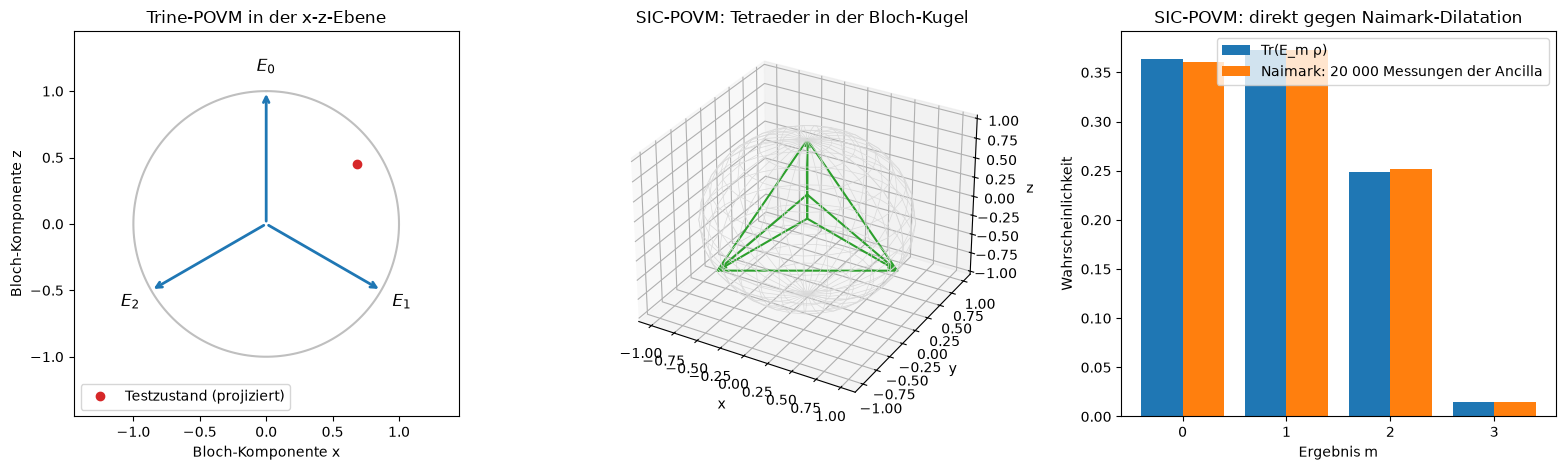

In [2]:
# Trine: drei Bloch-Richtungen im Abstand von 120° in der x-z-Ebene; SIC: die vier Ecken eines Tetraeders
n_trine = [np.array([np.sin(a), 0, np.cos(a)]) for a in 2 * np.pi * np.arange(3) / 3]
n_sic = [np.array([0, 0, 1.0])] + [np.array([np.sqrt(8) / 3 * np.cos(b), np.sqrt(8) / 3 * np.sin(b), -1 / 3])
                                   for b in 2 * np.pi * np.arange(3) / 3]
E_trine = [2 / 3 * from_bloch(v) for v in n_trine]          # (I + n·σ)/3
E_sic = [1 / 2 * from_bloch(v) for v in n_sic]              # (I + n·σ)/4
print("Trine ist ein POVM:", is_povm(E_trine), "| SIC ist ein POVM:", is_povm(E_sic))
print("Eigenwerte eines Trine-Elements:", np.round(np.linalg.eigvalsh(E_trine[0]), 3), "-> Rang 1, aber kein Projektor")
print("SIC informationell vollständig (4 linear unabhängige Elemente):",
      np.linalg.matrix_rank(np.array([E.ravel() for E in E_sic])) == 4)


def naimark_unitaer(M):
    """Unitäre U auf System ⊗ Ancilla mit U(|ψ>⊗|0>) = Σ_m M_m|ψ> ⊗ |m>."""
    n_m, d = len(M), M[0].shape[0]
    V = np.zeros((d * n_m, d), dtype=complex)
    for m, Mm in enumerate(M):
        V[m::n_m, :] = Mm                                    # Zeile i·n_m + m gehört zu |i>⊗|m>
    U = np.zeros((d * n_m, d * n_m), dtype=complex)
    U[:, ::n_m] = V                                          # Spalten zu |j>⊗|0>
    U[:, [k for k in range(d * n_m) if k % n_m]] = null_space(V.conj().T)   # orthonormal ergänzen
    return U


psi = bloch_ket(1.1, 0.7)                                    # ein beliebiger Testzustand
rho = dm(psi)
ergebnis = {}
for name, E in [("Trine", E_trine), ("SIC", E_sic)]:
    U = naimark_unitaer([psd_sqrt(Em) for Em in E])          # Lüders-Messoperatoren M_m = √E_m
    n_m = len(E)
    amp = (U @ np.kron(psi, np.eye(n_m)[0])).reshape(2, n_m) # Amplituden zu |i>⊗|m>
    p_naimark = (np.abs(amp) ** 2).sum(axis=0)               # projektive Messung der Ancilla
    p_povm = np.array([np.trace(Em @ rho).real for Em in E])
    ergebnis[name] = (p_povm, p_naimark)
    print(f"{name}: U ist {2 * n_m}x{2 * n_m} und unitär: {np.allclose(U.conj().T @ U, np.eye(2 * n_m))} | "
          f"Tr(E_m ρ) = {np.round(p_povm, 4)} | Naimark = {np.round(p_naimark, 4)}")

p_povm, p_naimark = ergebnis["SIC"]
haeufig = rng.multinomial(20_000, p_naimark) / 20_000        # 20 000 simulierte Messungen der Ancilla

fig = plt.figure(figsize=(16, 4.8))
ax1 = fig.add_subplot(1, 3, 1)
kreis = np.linspace(0, 2 * np.pi, 200)
ax1.plot(np.sin(kreis), np.cos(kreis), color="0.75")
for k, v in enumerate(n_trine):
    ax1.annotate("", xy=(v[0], v[2]), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="tab:blue", lw=2))
    ax1.text(1.18 * v[0], 1.18 * v[2], f"$E_{k}$", ha="center", va="center", fontsize=12)
r = bloch(rho)
ax1.plot(r[0], r[2], "o", color="tab:red", label="Testzustand (projiziert)")
ax1.set_aspect("equal")
ax1.set_xlim(-1.45, 1.45); ax1.set_ylim(-1.45, 1.45)
ax1.set_xlabel("Bloch-Komponente x"); ax1.set_ylabel("Bloch-Komponente z")
ax1.set_title("Trine-POVM in der x-z-Ebene")
ax1.legend(loc="lower left")

ax2 = fig.add_subplot(1, 3, 2, projection="3d")
uu, vv = np.mgrid[0:2 * np.pi:30j, 0:np.pi:15j]
ax2.plot_wireframe(np.cos(uu) * np.sin(vv), np.sin(uu) * np.sin(vv), np.cos(vv), color="0.85", lw=0.5)
for a, c in itertools.combinations(n_sic, 2):
    ax2.plot(*zip(a, c), color="tab:green")
for v in n_sic:
    ax2.quiver(0, 0, 0, *v, color="tab:green", arrow_length_ratio=0.1)
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("z")
ax2.set_title("SIC-POVM: Tetraeder in der Bloch-Kugel")

ax3 = fig.add_subplot(1, 3, 3)
m = np.arange(4)
ax3.bar(m - 0.2, p_povm, 0.4, label="Tr(E_m ρ)")
ax3.bar(m + 0.2, haeufig, 0.4, label="Naimark: 20 000 Messungen der Ancilla")
ax3.set_xticks(m)
ax3.set_xlabel("Ergebnis m"); ax3.set_ylabel("Wahrscheinlichkeit")
ax3.set_title("SIC-POVM: direkt gegen Naimark-Dilatation")
ax3.legend(loc="upper right")
plt.tight_layout()
plt.show()

* **Links** liegen die drei Trine-Richtungen im Abstand von 120° auf dem Einheitskreis der $x$-$z$-Ebene, dazu der Testzustand (rot). **Mitte:** die vier SIC-Richtungen bilden einen Tetraeder in der Bloch-Kugel. Weil sich die Richtungsvektoren jeweils zu null addieren, ist $\sum_kE_k = I$, und die Eigenwerte $\tfrac13(1\pm1)$ bzw. $\tfrac14(1\pm1)$ sind nichtnegativ.
* Die **Ausgabe** bestätigt beide als POVMs; ein Trine-Element hat die Eigenwerte 0 und 0,667: Rang 1, aber kein Projektor. Die vier SIC-Elemente sind linear unabhängig, also informationell vollständig.
* **Rechts** stehen für den Testzustand die SIC-Wahrscheinlichkeiten $\mathrm{Tr}(E_m\rho)$ neben den Häufigkeiten aus 20 000 Messungen der Ancilla. Die Naimark-Unitären sind $6\times6$ (Trine: Qubit mal 3 Ancilla-Zustände) und $8\times8$ (SIC) und unitär, und die exakten Wahrscheinlichkeiten stimmen auf vier Stellen überein (SIC: 0,3634, 0,3729, 0,2491, 0,0147).

##### *2. Das Zeigermodell: von stark zu schwach*

Wie sieht die Zeigerverteilung bei starker und schwacher Kopplung aus, und wie viel Information über $\sigma_z$ bekommt man für wie viel zerstörte Kohärenz? Vorher skizzieren: $\Phi(g/\sigma)$ und $e^{-g^2/2\sigma^2}$ gegen $g/\sigma$.

Ein Zeiger mit Breite $\sigma = 1$ wird mit der Stärke $g$ an $\sigma_z$ gekoppelt, im Zustand mit $p(+1) = 0{,}7$. Links: die Verteilung der Zeigerposition für $g/\sigma = 3$, $1$ und $0{,}2$, als Histogramm aus 20 000 Läufen und als Formel. Rechts: für viele $g$ die Wahrscheinlichkeit, $\pm1$ aus dem Vorzeichen von $q$ richtig zu raten, und der Faktor, um den die Kohärenz $\rho_{01}$ schrumpft (Theorie, Abschnitte 2 und 4).

**Hintergrund & Fachbegriffe:**
- **Zeiger:** ein Hilfssystem mit Ort $q$, dessen Position nach der Kopplung das Messergebnis anzeigt; anfangs ein Gauß-Paket der Breite $\sigma$.
- **Kopplungsstärke $g/\sigma$:** wie weit der Zeiger pro Eigenwert verschoben wird, gemessen in seiner eigenen Breite; groß heißt stark (projektiv), klein heißt schwach.
- **$\Phi$:** die Verteilungsfunktion der Standardnormalverteilung; $\Phi(g/\sigma)$ ist die Wahrscheinlichkeit, dass ein um $g$ verschobenes Gauß-Paket rechts von null liegt.
- **Verbleibende Kohärenz:** Ohne Ablesen wird $\rho_{01}$ mit dem Überlapp der beiden verschobenen Zeigerpakete multipliziert, $\int\phi_0(q-g)\phi_0(q+g)\,dq = e^{-g^2/2\sigma^2}$.

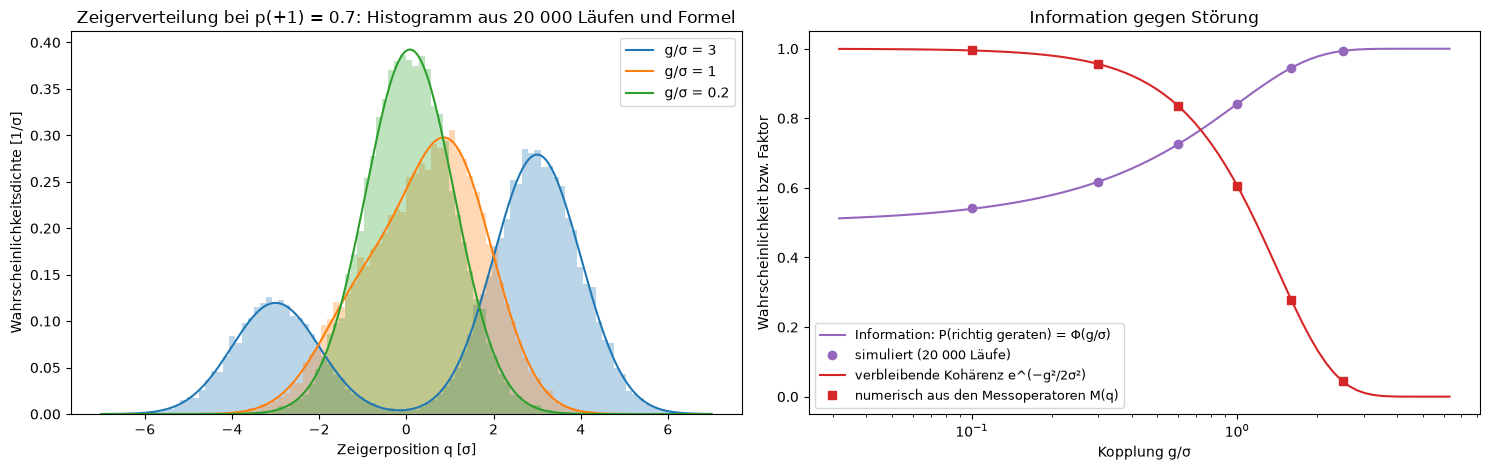

In [3]:
p_plus = 0.7                                               # Born-Wahrscheinlichkeit für σ_z = +1
sigma = 1.0                                                # Breite des Zeigers
q = np.linspace(-7, 7, 1401)
dq = q[1] - q[0]
gauss = lambda q, mu: np.exp(-(q - mu) ** 2 / (2 * sigma ** 2)) / np.sqrt(2 * np.pi * sigma ** 2)
phi0 = lambda q: (2 * np.pi * sigma ** 2) ** -0.25 * np.exp(-q ** 2 / (4 * sigma ** 2))   # Zeiger-Wellenfunktion

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for g, farbe in [(3.0, "tab:blue"), (1.0, "tab:orange"), (0.2, "tab:green")]:
    a = np.where(rng.random(20_000) < p_plus, 1, -1)       # Eigenwert nach der Born-Regel
    q_mess = g * a + sigma * rng.standard_normal(20_000)   # Zeiger um g·a verschoben, dazu seine Breite
    axes[0].hist(q_mess, bins=100, range=(-7, 7), density=True, alpha=0.3, color=farbe)
    axes[0].plot(q, p_plus * gauss(q, g) + (1 - p_plus) * gauss(q, -g), color=farbe, label=f"g/σ = {g:g}")
axes[0].set_xlabel("Zeigerposition q [σ]")
axes[0].set_ylabel("Wahrscheinlichkeitsdichte [1/σ]")
axes[0].set_title("Zeigerverteilung bei p(+1) = 0.7: Histogramm aus 20 000 Läufen und Formel")
axes[0].legend()

g_werte = np.logspace(-1.5, 0.8, 80)
g_test = np.array([0.1, 0.3, 0.6, 1.0, 1.6, 2.5])
# Information: Eigenzustand +1, geraten wird nach dem Vorzeichen des Zeigers
info_sim = [np.mean(g + sigma * rng.standard_normal(20_000) > 0) for g in g_test]
# Störung: Nichtdiagonalelement von |+x> nach der Messung ohne Ablesen, M(q) = diag(φ0(q−g), φ0(q+g))
koh_num = [sum(phi0(q - g) * phi0(q + g)) * dq for g in g_test]

axes[1].plot(g_werte, norm.cdf(g_werte / sigma), color="tab:purple", label="Information: P(richtig geraten) = Φ(g/σ)")
axes[1].plot(g_test, info_sim, "o", color="tab:purple", label="simuliert (20 000 Läufe)")
axes[1].plot(g_werte, np.exp(-g_werte ** 2 / (2 * sigma ** 2)), color="tab:red", label="verbleibende Kohärenz e^(−g²/2σ²)")
axes[1].plot(g_test, koh_num, "s", color="tab:red", label="numerisch aus den Messoperatoren M(q)")
axes[1].set_xscale("log")
axes[1].set_xlabel("Kopplung g/σ")
axes[1].set_ylabel("Wahrscheinlichkeit bzw. Faktor")
axes[1].set_title("Information gegen Störung")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

* **Links:** die Zeigerverteilung für $p(+1) = 0{,}7$. Bei $g/\sigma = 3$ (blau) sind es zwei getrennte Glocken bei $\pm3$ mit den Gewichten 0,7 und 0,3: eine projektive Messung. Bei $g/\sigma = 1$ (orange) überlappen sie stark, bei $0{,}2$ (grün) ist es fast eine einzige Glocke um $0{,}08$: Ein einzelnes Ablesen verrät kaum etwas.
* **Rechts:** gegen die Kopplung $g/\sigma$ (logarithmisch) die Information, die Wahrscheinlichkeit $\Phi(g/\sigma)$, aus dem Vorzeichen von $q$ richtig zu raten (lila), und die verbleibende Kohärenz $e^{-g^2/2\sigma^2}$ (rot). Simulation (Punkte) und direkte Rechnung aus den Messoperatoren (Quadrate) liegen auf den Kurven.
* Beide Kurven kreuzen sich: Mehr Information heißt weniger Kohärenz. Bei $g = \sigma$ rät man in 84 % der Fälle richtig und behält 61 % der Kohärenz; bei $g = 3\sigma$ rät man fast immer richtig, und die Kohärenz ist praktisch weg.

##### *3. Zwei Zustände unterscheiden: Helstrom und eindeutige Unterscheidung*

Wie gut lassen sich zwei reine Zustände mit Überlapp $c = \vert\langle\psi_0\vert\psi_1\rangle\vert$ unterscheiden, wenn man Fehler zulässt (Helstrom) und wenn man keine Fehler zulässt, aber „?“ sagen darf? Zum Vergleich die naive Messung: Projektor auf $\vert\psi_0\rangle$, „0“ bei Treffer. Vorher abschätzen: Bei $c = 0.6$, welche Fehlerrate hat Helstrom, wie oft sagt die eindeutige Messung „?“?

Für fünf Überlappe $c$ werden je 100 000 Läufe mit der Helstrom-Messung und mit dem eindeutigen POVM simuliert und mit den Formeln verglichen; die Linien zeigen die Formeln für alle $c$, dazu die naive Messung (Theorie, Abschnitt 3).

**Hintergrund & Fachbegriffe:**
- **Überlapp $c$:** $\vert\langle\psi_0\vert\psi_1\rangle\vert$; 0 heißt orthogonal (perfekt unterscheidbar), 1 heißt gleich.
- **Helstrom-Messung:** der Projektor auf den positiven Eigenraum von $\Gamma = p_0\rho_0 - p_1\rho_1$; er maximiert $P_\text{succ} = p_1 + \mathrm{Tr}(E_0\Gamma)$ und erreicht $\tfrac12(1 + \Vert\Gamma\Vert_1)$. Für reine Zustände mit gleichen Priors ist der Fehler $\tfrac12(1 - \sqrt{1 - c^2})$.
- **Eindeutige Unterscheidung:** ein POVM mit den Ergebnissen „0“, „1“, „?“, dessen Element „0“ senkrecht auf $\vert\psi_1\rangle$ steht und umgekehrt; damit es ein POVM bleibt ($E_?\ge0$), muss „?“ mit Wahrscheinlichkeit $c$ kommen.
- **Naive Messung:** projektiv auf $\vert\psi_0\rangle$; sie irrt sich nur, wenn $\vert\psi_1\rangle$ vorlag und trotzdem „0“ kam, mit Wahrscheinlichkeit $\tfrac12c^2$.

c = 0.20: Helstrom-Fehler 0.0103 (Formel 0.0101) | eindeutig: Fehler 0.0000, „?“ 0.2050 (Formel 0.20) | E_? ≥ 0: True
c = 0.40: Helstrom-Fehler 0.0421 (Formel 0.0417) | eindeutig: Fehler 0.0000, „?“ 0.4029 (Formel 0.40) | E_? ≥ 0: True
c = 0.60: Helstrom-Fehler 0.1007 (Formel 0.1000) | eindeutig: Fehler 0.0000, „?“ 0.5988 (Formel 0.60) | E_? ≥ 0: True
c = 0.80: Helstrom-Fehler 0.2001 (Formel 0.2000) | eindeutig: Fehler 0.0000, „?“ 0.7996 (Formel 0.80) | E_? ≥ 0: True
c = 0.95: Helstrom-Fehler 0.3426 (Formel 0.3439) | eindeutig: Fehler 0.0000, „?“ 0.9539 (Formel 0.95) | E_? ≥ 0: True


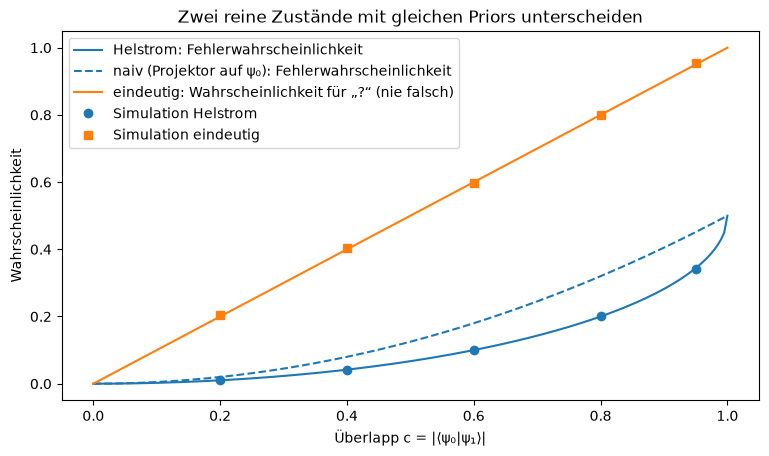

In [4]:
def senkrecht(psi):
    """Der zu einem Qubit-Zustand orthogonale Zustand."""
    return np.array([-psi[1].conj(), psi[0].conj()])


c_werte = np.linspace(0, 1, 201)
sim = []
for c in [0.2, 0.4, 0.6, 0.8, 0.95]:
    psi0, psi1 = bloch_ket(0), bloch_ket(2 * np.arccos(c))            # Überlapp |<ψ0|ψ1>| = c
    rho0, rho1 = dm(psi0), dm(psi1)
    N = 20_000
    i = rng.integers(0, 2, N)                                          # präparierter Zustand, gleiche Priors

    # Helstrom: Projektor auf den positiven Eigenraum von Γ = ½ρ0 − ½ρ1 heißt „0“
    w, V = np.linalg.eigh(0.5 * rho0 - 0.5 * rho1)
    P0 = V[:, w > 0] @ V[:, w > 0].conj().T
    p_null = np.where(i == 0, np.trace(P0 @ rho0).real, np.trace(P0 @ rho1).real)
    fehler_hel = np.mean((rng.random(N) < p_null) != (i == 0))

    # eindeutige Unterscheidung: E0 ∝ |ψ1⊥><ψ1⊥|, E1 ∝ |ψ0⊥><ψ0⊥|, der Rest heißt „?“
    a = 1 / (1 + c)
    E0, E1 = a * dm(senkrecht(psi1)), a * dm(senkrecht(psi0))
    E_usd = [E0, E1, I2 - E0 - E1]
    antwort = np.empty(N, dtype=int)
    for j, r in enumerate((rho0, rho1)):
        p = np.clip([np.trace(E @ r).real for E in E_usd], 0, None)
        antwort[i == j] = rng.choice(3, size=(i == j).sum(), p=p / p.sum())
    fehler_usd = np.mean((antwort < 2) & (antwort != i))
    frage_usd = np.mean(antwort == 2)
    sim.append((c, fehler_hel, frage_usd))
    print(f"c = {c:.2f}: Helstrom-Fehler {fehler_hel:.4f} (Formel {0.5 * (1 - np.sqrt(1 - c ** 2)):.4f}) | "
          f"eindeutig: Fehler {fehler_usd:.4f}, „?“ {frage_usd:.4f} (Formel {c:.2f}) | "
          f"E_? ≥ 0: {np.linalg.eigvalsh(E_usd[2]).min() > -1e-12}")
sim = np.array(sim)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(c_werte, 0.5 * (1 - np.sqrt(1 - c_werte ** 2)), color="tab:blue", label="Helstrom: Fehlerwahrscheinlichkeit")
ax.plot(c_werte, c_werte ** 2 / 2, "--", color="tab:blue", label="naiv (Projektor auf ψ₀): Fehlerwahrscheinlichkeit")
ax.plot(c_werte, c_werte, color="tab:orange", label="eindeutig: Wahrscheinlichkeit für „?“ (nie falsch)")
ax.plot(sim[:, 0], sim[:, 1], "o", color="tab:blue", label="Simulation Helstrom")
ax.plot(sim[:, 0], sim[:, 2], "s", color="tab:orange", label="Simulation eindeutig")
ax.set_xlabel("Überlapp c = |⟨ψ₀|ψ₁⟩|")
ax.set_ylabel("Wahrscheinlichkeit")
ax.set_title("Zwei reine Zustände mit gleichen Priors unterscheiden")
ax.legend()
plt.show()

* Das Bild zeigt gegen den Überlapp $c$ drei Größen: den Helstrom-Fehler $\tfrac12(1 - \sqrt{1 - c^2})$ (blau), den Fehler der naiven Messung $\tfrac12c^2$ (blau gestrichelt) und die Wahrscheinlichkeit für „?“ bei eindeutiger Unterscheidung, gleich $c$ (orange). Die Punkte sind die Simulation mit je 100 000 Läufen.
* Für kleine $c$ macht die naive Messung doppelt so viele Fehler wie Helstrom ($\tfrac12c^2$ gegen etwa $\tfrac14c^2$); bei $c\to1$ nähern sich beide $\tfrac12$, reines Raten.
* Die **Ausgabe** bestätigt die Formeln (bei $c = 0{,}6$: Helstrom-Fehler 0,1007 gegen 0,1000) und zeigt: Die eindeutige Messung irrt sich in keinem einzigen Lauf, sagt aber bei $c = 0{,}6$ in 59,9 % der Fälle „?“. $E_?\ge0$ gilt jeweils, die Messung ist also gültig.

##### *4. Drei Zustände: SDP gegen Pretty-Good-Measurement*

Drei reine Qubit-Zustände mit Bloch-Vektoren in der x-z-Ebene bei den Winkeln $0$ und $\pm\beta$, gleiche Priors. Welche Erfolgswahrscheinlichkeit erreicht die beste Messung (SDP), und wie nahe kommt die PGM? Bei $\beta = 120°$ ist das die Trine; vorher überlegen, warum dort beide gleich sein müssen.

Für Winkel $\beta$ von $0°$ bis $180°$ wird die beste Erfolgswahrscheinlichkeit als semidefinites Programm mit cvxpy berechnet und mit der Pretty-Good-Measurement und der Schranke $P_\text{opt}^2$ verglichen. Zum Schluss dasselbe für drei zufällige gemischte Zustände mit ungleichen Priors (Theorie, Abschnitt 3).

**Hintergrund & Fachbegriffe:**
- **Semidefinites Programm (SDP):** eine Optimierung über positiv semidefinite Matrizen mit linearen Nebenbedingungen; hier über alle POVMs $\{E_i\}$. Es liefert das exakte Optimum, aber nur numerisch.
- **Pretty-Good-Measurement (PGM):** $E_i = \rho^{-1/2}p_i\rho_i\rho^{-1/2}$ mit $\rho = \sum_ip_i\rho_i$; in geschlossener Form, für symmetrische Zustandsmengen optimal, allgemein mindestens $P_\text{opt}^2$ (Barnum–Knill).
- **Trine:** die drei Zustände bei $0$ und $\pm120°$, symmetrisch unter Drehung um $120°$; deshalb ist die PGM dort optimal.
- **Obergrenze $d/3$:** Für ein Qubit ist $\sum_ip_i\mathrm{Tr}(E_i\rho_i)\le\tfrac13\sum_i\mathrm{Tr}\,E_i = \tfrac23$, wenn alle $\rho_i$ rein sind und die Priors $\tfrac13$.

Trine (β = 120°): SDP 0.6667, PGM 0.6667, erwartet 2/3
PGM ≥ SDP² überall: True
Zufällige gemischte Zustände, Priors [0.5, 0.3, 0.2]: SDP 0.6201, PGM 0.5388


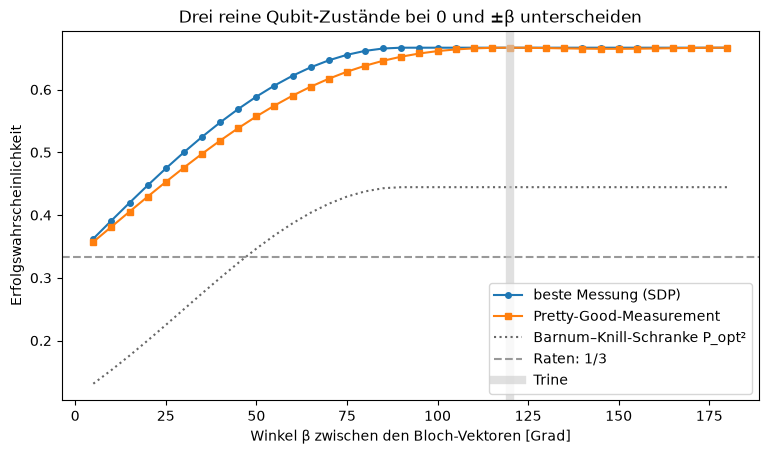

In [5]:
def sdp_unterscheidung(rhos, ps):
    """Beste Erfolgswahrscheinlichkeit max Σ p_i Tr(E_i ρ_i) unter E_i ≥ 0, Σ E_i = I."""
    d = rhos[0].shape[0]
    E = [cp.Variable((d, d), hermitian=True) for _ in rhos]
    ziel = cp.Maximize(cp.real(sum(p * cp.trace(r @ Ei) for p, r, Ei in zip(ps, rhos, E))))
    problem = cp.Problem(ziel, [Ei >> 0 for Ei in E] + [sum(E) == np.eye(d)])
    problem.solve()
    return problem.value


def pgm(rhos, ps):
    """Erfolgswahrscheinlichkeit der Pretty-Good-Measurement E_i = ρ^(−1/2) p_i ρ_i ρ^(−1/2)."""
    rho = sum(p * r for p, r in zip(ps, rhos))
    w, V = np.linalg.eigh(rho)
    inv_wurzel = (V * np.where(w > 1e-12, 1 / np.sqrt(np.abs(w) + 1e-300), 0)) @ V.conj().T
    E = [inv_wurzel @ (p * r) @ inv_wurzel for p, r in zip(ps, rhos)]
    E[0] = E[0] + np.eye(len(w)) - sum(E)          # Kern von ρ zu E_0 (ändert die Erfolgswahrscheinlichkeit nicht)
    assert is_povm(E)
    return sum(p * np.trace(r @ Ei).real for p, r, Ei in zip(ps, rhos, E))


beta = np.radians(np.linspace(5, 180, 36))
P_sdp, P_pgm = [], []
for bt in beta:
    rhos = [from_bloch([np.sin(a), 0, np.cos(a)]) for a in (0, bt, -bt)]
    P_sdp.append(sdp_unterscheidung(rhos, [1 / 3] * 3))
    P_pgm.append(pgm(rhos, [1 / 3] * 3))
P_sdp, P_pgm = np.array(P_sdp), np.array(P_pgm)
k120 = np.argmin(abs(np.degrees(beta) - 120))
print(f"Trine (β = 120°): SDP {P_sdp[k120]:.4f}, PGM {P_pgm[k120]:.4f}, erwartet 2/3")
print("PGM ≥ SDP² überall:", np.all(P_pgm >= P_sdp ** 2 - 1e-6))

# ein unsymmetrischer Fall: drei zufällige gemischte Zustände mit ungleichen Priors
rhos = [from_bloch(v / np.linalg.norm(v) * rng.uniform(0.5, 1)) for v in rng.normal(size=(3, 3))]
ps = [0.5, 0.3, 0.2]
print(f"Zufällige gemischte Zustände, Priors {ps}: SDP {sdp_unterscheidung(rhos, ps):.4f}, PGM {pgm(rhos, ps):.4f}")

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(np.degrees(beta), P_sdp, "o-", ms=4, label="beste Messung (SDP)")
ax.plot(np.degrees(beta), P_pgm, "s-", ms=4, label="Pretty-Good-Measurement")
ax.plot(np.degrees(beta), P_sdp ** 2, ":", color="0.4", label="Barnum–Knill-Schranke P_opt²")
ax.axhline(1 / 3, color="0.6", ls="--", label="Raten: 1/3")
ax.axvline(120, color="0.8", lw=6, alpha=0.6, label="Trine")
ax.set_xlabel("Winkel β zwischen den Bloch-Vektoren [Grad]")
ax.set_ylabel("Erfolgswahrscheinlichkeit")
ax.set_title("Drei reine Qubit-Zustände bei 0 und ±β unterscheiden")
ax.legend()
plt.show()

* Das Bild zeigt gegen den Winkel $\beta$ die beste Erfolgswahrscheinlichkeit (SDP, Kreise), die der Pretty-Good-Measurement (Quadrate), die Barnum–Knill-Schranke $P_\text{opt}^2$ (gepunktet) und das Raten $\tfrac13$ (gestrichelt); der graue Streifen markiert die Trine bei 120°.
* Bei kleinem $\beta$ sind die drei Zustände fast gleich, und beide Messungen liegen kaum über dem Raten. Ab etwa $85°$ erreicht die beste Messung $\tfrac23$, die Obergrenze für drei reine Qubit-Zustände mit gleichen Priors; die PGM liegt bis etwa $110°$ darunter und erreicht das Optimum erst ab der symmetrischen Trine. Die Schranke $P_\text{opt}^2$ endet bei $\tfrac49$ und liegt überall weit unter der PGM.
* Die **Ausgabe** nennt für die Trine SDP und PGM beide 0,6667, und $P_\text{PGM}\ge P_\text{opt}^2$ gilt überall. Für drei zufällige gemischte Zustände mit Priors 0,5, 0,3, 0,2 liegt die PGM mit 0,5388 deutlich unter dem Optimum 0,6201: Ohne Symmetrie lohnt das SDP.

##### *5. Unschärfe und gemeinsame Messbarkeit*

Welche Untergrenzen setzen Robertson, Schrödinger und Maassen–Uffink für $\sigma_x$ und $\sigma_z$, und welche unscharfen Versionen von $\sigma_x$ und $\sigma_z$ kann ein einziges POVM gemeinsam messen? Vorher überlegen: Was sagt Robertson für Zustände in der x-z-Ebene?

Drei Bilder: (links) für reine Zustände rund um den Kreis in der $x$-$z$-Ebene die Entropiesumme $H(X) + H(Z)$ und das Produkt $\Delta X\cdot\Delta Z$ mit ihren Schranken; (Mitte) für zufällige reine und gemischte Zustände beide Seiten der Schrödinger- und der Robertson-Relation; (rechts) der kleinste Eigenwert des gemeinsamen POVM $G_{ab}$ für alle Schärfen $\eta_x$, $\eta_z$ (Theorie, Abschnitt 4).

**Hintergrund & Fachbegriffe:**
- **Robertson:** $\Delta A\,\Delta B\ge\tfrac12\vert\langle[A,B]\rangle\vert$; für $\sigma_x$, $\sigma_z$ ist die rechte Seite $\vert\langle\sigma_y\rangle\vert$, also null für alle Zustände in der $x$-$z$-Ebene.
- **Schrödinger:** ergänzt die Kovarianz; aus Cauchy–Schwarz für $(A - \langle A\rangle)\psi$ und $(B - \langle B\rangle)\psi$. Für reine Qubit-Zustände wird sie zur Gleichung.
- **Maassen–Uffink:** $H(X) + H(Z)\ge-2\log_2c$, unabhängig vom Zustand; für $\sigma_x$ und $\sigma_z$ ist $c = 1/\sqrt2$, also 1 Bit.
- **Gemeinsame Messbarkeit:** Zwei POVMs sind gemeinsam messbar, wenn ein einziges POVM beide als Ränder hat; $G_{ab} = \tfrac14(I + a\eta_x\sigma_x + b\eta_z\sigma_z)$ ist genau dann positiv, wenn $\eta_x^2 + \eta_z^2\le1$.

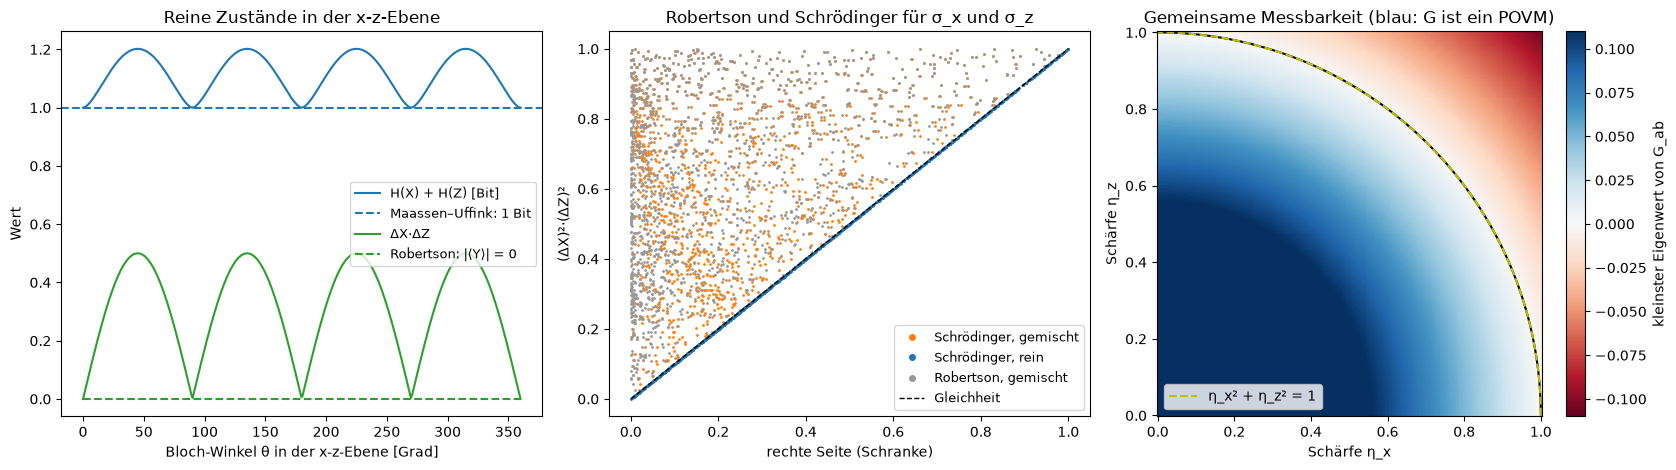

Minimum von H(X) + H(Z) auf dem Kreis: 1.0000 Bit


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) reine Zustände auf dem Großkreis in der x-z-Ebene
theta = np.linspace(0, 2 * np.pi, 400)
HX, HZ, produkt, robertson = [], [], [], []
for t in theta:
    r = from_bloch([np.sin(t), 0, np.cos(t)])
    px, pz = np.trace(r @ (I2 + X) / 2).real, np.trace(r @ (I2 + Z) / 2).real
    HX.append(shannon([px, 1 - px])); HZ.append(shannon([pz, 1 - pz]))
    x, y, z = bloch(r)
    produkt.append(np.sqrt((1 - x ** 2) * (1 - z ** 2))); robertson.append(abs(y))
ax = axes[0]
ax.plot(np.degrees(theta), np.array(HX) + np.array(HZ), label="H(X) + H(Z) [Bit]")
ax.axhline(1, color="tab:blue", ls="--", label="Maassen–Uffink: 1 Bit")
ax.plot(np.degrees(theta), produkt, color="tab:green", label="ΔX·ΔZ")
ax.plot(np.degrees(theta), robertson, color="tab:green", ls="--", label="Robertson: |⟨Y⟩| = 0")
ax.set_xlabel("Bloch-Winkel θ in der x-z-Ebene [Grad]")
ax.set_ylabel("Wert")
ax.set_title("Reine Zustände in der x-z-Ebene")
ax.legend(fontsize=9, loc="center right")

# (b) zufällige Zustände: linke Seite gegen rechte Seite der Relationen
v = rng.normal(size=(1500, 3)); v /= np.linalg.norm(v, axis=1, keepdims=True)
rein = v                                                     # auf der Kugel
gemischt = v * rng.uniform(0, 1, (1500, 1)) ** (1 / 3)      # gleichverteilt in der Kugel
ax = axes[1]
for punkte, name, farbe in [(gemischt, "gemischt", "tab:orange"), (rein, "rein", "tab:blue")]:
    x, y, z = punkte.T
    links = (1 - x ** 2) * (1 - z ** 2)                      # (ΔX)²(ΔZ)²
    ax.plot(x ** 2 * z ** 2 + y ** 2, links, ".", ms=2, color=farbe, label=f"Schrödinger, {name}")
x, y, z = gemischt.T
ax.plot(y ** 2, (1 - x ** 2) * (1 - z ** 2), ".", ms=2, color="0.6", label="Robertson, gemischt")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Gleichheit")
ax.set_xlabel("rechte Seite (Schranke)")
ax.set_ylabel("(ΔX)²·(ΔZ)²")
ax.set_title("Robertson und Schrödinger für σ_x und σ_z")
ax.legend(fontsize=9, markerscale=4)

# (c) gemeinsame Messbarkeit: kleinster Eigenwert von G_ab = (I + a η_x σ_x + b η_z σ_z)/4
eta = np.linspace(0, 1, 201)
lam_min = np.array([[min(np.linalg.eigvalsh((I2 + a * ex * X + bb * ez * Z) / 4).min()
                         for a in (1, -1) for bb in (1, -1)) for ex in eta] for ez in eta])
ax = axes[2]
bild = ax.pcolormesh(eta, eta, lam_min, cmap="RdBu", vmin=-0.11, vmax=0.11, shading="auto")
ax.contour(eta, eta, lam_min, levels=[0], colors="k")
ax.plot(np.cos(np.linspace(0, np.pi / 2, 100)), np.sin(np.linspace(0, np.pi / 2, 100)), "y--", label="η_x² + η_z² = 1")
plt.colorbar(bild, ax=ax, label="kleinster Eigenwert von G_ab")
ax.set_aspect("equal")
ax.set_xlabel("Schärfe η_x"); ax.set_ylabel("Schärfe η_z")
ax.set_title("Gemeinsame Messbarkeit (blau: G ist ein POVM)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
print(f"Minimum von H(X) + H(Z) auf dem Kreis: {min(np.array(HX) + np.array(HZ)):.4f} Bit")

* **Links:** für reine Zustände rund um den Kreis in der $x$-$z$-Ebene. Das Produkt $\Delta X\cdot\Delta Z$ (grün) fällt an den Eigenzuständen auf null, und die Robertson-Schranke $\vert\langle Y\rangle\vert$ ist überall null: Sie sagt hier nichts. Die Entropiesumme $H(X) + H(Z)$ bleibt dagegen immer über 1 Bit und erreicht es genau an den Eigenzuständen (Ausgabe: Minimum 1,0000 Bit).
* **Mitte:** linke Seite $(\Delta X)^2(\Delta Z)^2$ gegen die Schranke. Reine Zustände (blau) liegen genau auf der Diagonalen: Die Schrödinger-Relation ist für sie eine Gleichung. Gemischte (orange) liegen darüber; die Robertson-Punkte (grau) liegen meist weit darüber, die Schranke ist schwach.
* **Rechts:** der kleinste Eigenwert von $G_{ab}$ über den Schärfen $\eta_x$, $\eta_z$. Blau (positiv) heißt, dass das gemeinsame POVM existiert; die schwarze Nulllinie fällt genau auf den Viertelkreis $\eta_x^2 + \eta_z^2 = 1$ (gelb gestrichelt). Scharfe $\sigma_x$ und $\sigma_z$ zugleich ($\eta_x = \eta_z = 1$) liegen weit außerhalb.

##### *6. Schwache Messung und Weak Value*

Was zeigt ein schwach gekoppelter Zeiger nach Postselektion, und kann seine mittlere Verschiebung außerhalb der Eigenwerte $\pm1$ von $\sigma_z$ liegen? Anfangszustand $\vert{+x}\rangle$, Postselektion auf einen Zustand, der um den kleinen Winkel $\varepsilon$ von der Orthogonalität abweicht. Vorher ausrechnen: $A_w = \cot\varepsilon$.

Der Zeiger wird mit $g/\sigma = 0{,}05$ (schwach) oder $3$ (stark) gekoppelt, danach wird nur der Anteil der Läufe behalten, in denen die Postselektion gelingt ($\varepsilon = 0{,}1$). Links: die Zeigerverteilung nach Postselektion, rechts: die exakte mittlere Verschiebung, geteilt durch $g$, für Kopplungen von $10^{-2{,}5}$ bis $10$ (Theorie, Abschnitt 5).

**Hintergrund & Fachbegriffe:**
- **Postselektion:** nur die Läufe auswerten, in denen eine spätere projektive Messung ein bestimmtes Ergebnis $\vert\phi\rangle$ liefert; die anderen werden verworfen.
- **Weak Value:** in erster Ordnung in $g$ ist der Zeiger nach Postselektion um $g\,\mathrm{Re}A_w$ verschoben, $A_w = \langle\phi\vert A\vert\psi\rangle/\langle\phi\vert\psi\rangle$; der Nenner ist für fast orthogonale Zustände klein, daher der große Wert.
- **Gültigkeit der schwachen Näherung:** nur solange $g\vert A_w\vert\ll\sigma$; bei stärkerer Kopplung zerstört die Messung selbst die Postselektion, und der Zeiger zeigt wieder Eigenwerte.

Weak Value A_w = 9.967 (cot ε = 9.967), Wahrscheinlichkeit der Postselektion 0.0100


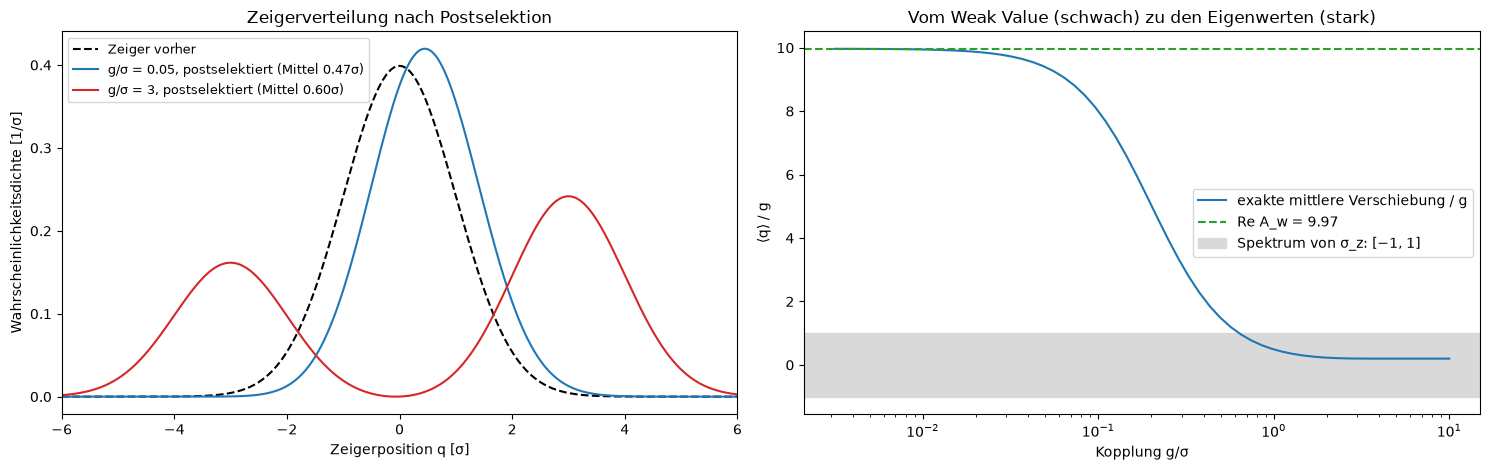

nötig: etwa 101 postselektierte Läufe, also etwa 10101 Läufe insgesamt


In [7]:
eps = 0.1
psi_i = np.array([1, 1]) / np.sqrt(2)                                   # |+x>
psi_f = np.array([np.cos(np.pi / 4 - eps), -np.sin(np.pi / 4 - eps)])   # fast orthogonal zu |+x>
A_w = (psi_f.conj() @ Z @ psi_i) / (psi_f.conj() @ psi_i)
print(f"Weak Value A_w = {A_w.real:.3f} (cot ε = {1 / np.tan(eps):.3f}), "
      f"Wahrscheinlichkeit der Postselektion {abs(psi_f.conj() @ psi_i) ** 2:.4f}")

sigma = 1.0
q = np.linspace(-40, 40, 16001)
dq = q[1] - q[0]
phi0 = lambda x: (2 * np.pi * sigma ** 2) ** -0.25 * np.exp(-x ** 2 / (4 * sigma ** 2))


def zeiger_nach_postselektion(g):
    """Exakte Zeigerverteilung nach U = exp(−i g σ_z ⊗ p) und Postselektion auf psi_f (nicht nur erste Ordnung)."""
    amp = psi_f.conj()[0] * psi_i[0] * phi0(q - g) + psi_f.conj()[1] * psi_i[1] * phi0(q + g)
    dichte = np.abs(amp) ** 2
    p_post = dichte.sum() * dq
    return dichte / p_post, p_post


fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
ax.plot(q, phi0(q) ** 2, "k--", label="Zeiger vorher")
for g, farbe in [(0.05, "tab:blue"), (3.0, "tab:red")]:
    dichte, p_post = zeiger_nach_postselektion(g)
    ax.plot(q, dichte, color=farbe, label=f"g/σ = {g:g}, postselektiert (Mittel {np.sum(q * dichte) * dq:.2f}σ)")
ax.set_xlim(-6, 6)
ax.set_xlabel("Zeigerposition q [σ]"); ax.set_ylabel("Wahrscheinlichkeitsdichte [1/σ]")
ax.set_title("Zeigerverteilung nach Postselektion")
ax.legend(fontsize=9)

g_werte = np.logspace(-2.5, 1, 60)
verschiebung = []
for g in g_werte:
    dichte, _ = zeiger_nach_postselektion(g)
    verschiebung.append(np.sum(q * dichte) * dq / g)                    # mittlere Verschiebung in Einheiten von g
ax = axes[1]
ax.plot(g_werte, verschiebung, label="exakte mittlere Verschiebung / g")
ax.axhline(A_w.real, color="tab:green", ls="--", label=f"Re A_w = {A_w.real:.2f}")
ax.axhspan(-1, 1, color="0.85", label="Spektrum von σ_z: [−1, 1]")
ax.set_xscale("log")
ax.set_xlabel("Kopplung g/σ"); ax.set_ylabel("⟨q⟩ / g")
ax.set_title("Vom Weak Value (schwach) zu den Eigenwerten (stark)")
ax.legend()
plt.tight_layout()
plt.show()

# Wie viele Läufe braucht man, um die Verschiebung 0.5σ bei g = 0.05 mit 5 Standardabweichungen zu sehen?
n_post = (5 * sigma / (0.05 * A_w.real)) ** 2
print(f"nötig: etwa {n_post:.0f} postselektierte Läufe, also etwa {n_post / abs(psi_f.conj() @ psi_i) ** 2:.0f} Läufe insgesamt")

* **Links:** die Zeigerverteilung vor der Kopplung (schwarz gestrichelt) und nach Postselektion. Bei schwacher Kopplung ($g/\sigma = 0{,}05$, blau) ist das ganze Paket um etwa $0{,}5\sigma$ verschoben, obwohl ein Eigenwert $\pm1$ nur $\pm0{,}05\sigma$ ergäbe; bei starker Kopplung ($g/\sigma = 3$, rot) zeigt der Zeiger wieder die Eigenwerte.
* **Rechts:** die exakte mittlere Verschiebung, geteilt durch $g$, gegen die Kopplung. Für kleine $g$ liegt sie beim Weak Value $\mathrm{Re}A_w = 9{,}97$, weit außerhalb des grauen Bands $[-1, 1]$ der Eigenwerte. Ab $g/\sigma\approx0{,}1$, wenn $gA_w$ vergleichbar mit $\sigma$ wird, fällt sie ab und landet bei starker Kopplung im Spektrum.
* Die **Ausgabe** zeigt den Preis: $A_w = \cot\varepsilon = 9{,}967$, aber die Postselektion gelingt nur in 1 % der Läufe. Um die Verschiebung $0{,}5\sigma$ bei $g = 0{,}05\sigma$ mit fünf Standardabweichungen zu sehen, braucht man etwa 101 postselektierte Läufe, also rund 10 000 insgesamt.

##### *7. Kontinuierliche Messung: der Kollaps als Zufallsweg*

Wie sieht der Kollaps aus, wenn man $\sigma_z$ kontinuierlich und schwach misst, und wie oft endet ein Lauf bei $+1$? Anfangszustand mit $z_0 = 0.4$, also Born-Wahrscheinlichkeit $p(+1) = 0.7$. Vorher vorhersagen: Wie verhält sich der Mittelwert von $z$ über viele Läufe, wie der Mittelwert von $x$?

1000 Läufe der stochastischen Mastergleichung mit $L = \sqrt\kappa\,\sigma_z$ und $H = 0$ starten im reinen Zustand mit $z_0 = 0{,}4$ und laufen bis $t = 4/\kappa$. Links: 14 Trajektorien von $z = \langle\sigma_z\rangle$, Mitte: die Endwerte aller Läufe, rechts: die Mittelwerte von $z$ und $x$ über alle Läufe (Theorie, Abschnitt 6).

**Hintergrund & Fachbegriffe:**
- **Trajektorie:** der Zustand eines einzelnen Laufs, der das Messsignal kennt; er wandert zufällig, weil das Signal verrauscht ist.
- **Wiener-Rauschen $dW$:** unabhängige Gauß-Zuwächse mit Mittelwert 0 und Varianz $dt$, das Rauschen des Messsignals.
- **Kollaps als Diffusion:** Für diese Messung gilt $dz = 2\sqrt\kappa\,(1 - z^2)\,dW$; das Rauschen verschwindet nur bei $z = \pm1$, dort bleibt jeder Lauf stehen.
- **Martingal:** eine Größe ohne Drift, deren Erwartungswert konstant bleibt. Weil $\mathbb E z_t = z_0$ und jeder Lauf bei $\pm1$ endet, folgt $P(+1) = \tfrac12(1 + z_0)$: die Born-Regel.

Anteil der Läufe bei z = +1: 0.697 (Born: 0.70); |z| > 0.99 am Ende: 1.000


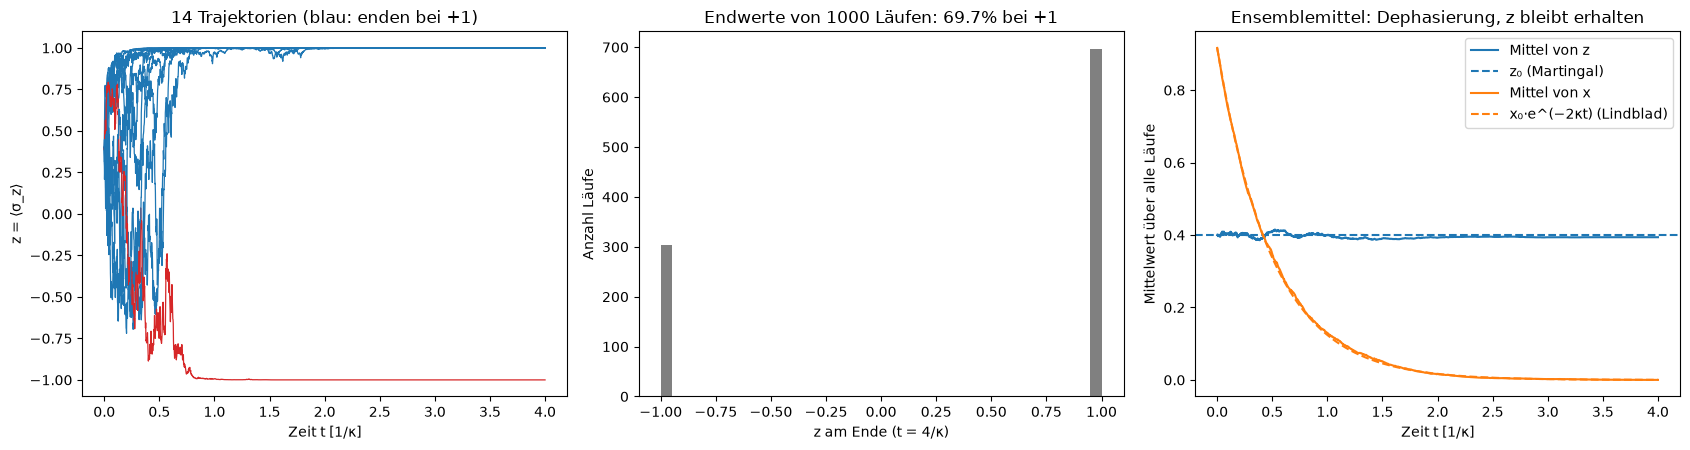

In [8]:
kappa, dt, T, n_traj = 1.0, 0.002, 4.0, 1000
z0 = 0.4
rho = np.repeat(dm([np.sqrt((1 + z0) / 2), np.sqrt((1 - z0) / 2)])[None], n_traj, axis=0)
L = np.sqrt(kappa) * Z
t = np.arange(int(T / dt) + 1) * dt
z = np.empty((len(t), n_traj)); x = np.empty_like(z)
z[0], x[0] = z0, np.sqrt(1 - z0 ** 2)
for k in range(1, len(t)):
    rho, _ = sme_step(rho, 0 * I2, L, dt)
    z[k] = np.real(rho[:, 0, 0] - rho[:, 1, 1])
    x[k] = 2 * np.real(rho[:, 0, 1])

oben = z[-1] > 0
print(f"Anteil der Läufe bei z = +1: {oben.mean():.3f} (Born: {(1 + z0) / 2:.2f}); "
      f"|z| > 0.99 am Ende: {np.mean(abs(z[-1]) > 0.99):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for j in range(14):
    axes[0].plot(t, z[:, j], lw=0.9, color="tab:blue" if oben[j] else "tab:red")
axes[0].set_xlabel("Zeit t [1/κ]"); axes[0].set_ylabel("z = ⟨σ_z⟩")
axes[0].set_title("14 Trajektorien (blau: enden bei +1)")

axes[1].hist(z[-1], bins=40, range=(-1, 1), color="0.5")
axes[1].set_xlabel("z am Ende (t = 4/κ)"); axes[1].set_ylabel("Anzahl Läufe")
axes[1].set_title(f"Endwerte von {n_traj} Läufen: {oben.mean():.1%} bei +1")

axes[2].plot(t, z.mean(axis=1), label="Mittel von z")
axes[2].axhline(z0, color="tab:blue", ls="--", label="z₀ (Martingal)")
axes[2].plot(t, x.mean(axis=1), label="Mittel von x")
axes[2].plot(t, x[0, 0] * np.exp(-2 * kappa * t), "--", color="tab:orange", label="x₀·e^(−2κt) (Lindblad)")
axes[2].set_xlabel("Zeit t [1/κ]"); axes[2].set_ylabel("Mittelwert über alle Läufe")
axes[2].set_title("Ensemblemittel: Dephasierung, z bleibt erhalten")
axes[2].legend()
plt.tight_layout()
plt.show()

* **Links:** 14 Trajektorien von $z$; alle starten bei 0,4, wandern zufällig und laufen an $+1$ (blau) oder $-1$ an, wo das Rauschen verschwindet. Der Kollaps ist hier kein Sprung, sondern ein Zufallsweg von etwa $1/\kappa$ Dauer.
* **Mitte:** die Endwerte aller 1000 Läufe bei $t = 4/\kappa$, nur bei $\pm1$. Die **Ausgabe** nennt 69,7 % bei $+1$ gegen die Born-Wahrscheinlichkeit 70 %, und alle Läufe haben $\vert z\vert>0{,}99$.
* **Rechts:** das Mittel von $z$ bleibt bei $z_0 = 0{,}4$ (Martingal), das Mittel von $x$ fällt wie $x_0e^{-2\kappa t}$. Die Born-Regel und die Dephasierung der Lindblad-Gleichung kommen aus derselben stochastischen Gleichung: das eine im einzelnen Lauf, das andere im Mittel.

##### *8. Eine Mastergleichung, zwei Arten von Trajektorien*

Ein Qubit im Zustand $(\vert0\rangle + \vert1\rangle)/\sqrt2$ zerfällt spontan nach $\vert0\rangle$ ($L = \sqrt\gamma\,\sigma_-$). Wie sehen die Trajektorien der angeregten Besetzung aus, wenn man die Emission mit einem Photodetektor zählt (Sprünge), und wie bei Homodyn-Detektion (Diffusion)? Vorher überlegen: Was passiert mit dem Zustand, solange der Photodetektor nicht klickt?

Je 2000 Läufe mit Photodetektion (Monte-Carlo-Wellenfunktion: Klick mit Wahrscheinlichkeit $\gamma P_e\,dt$, dazwischen $H_\text{eff}$ und Normierung) und mit Homodyn-Detektion (stochastische Mastergleichung) laufen bis $t = 5/\gamma$. Links und Mitte: einzelne Trajektorien der angeregten Besetzung $P_e$, rechts: die Mittelwerte und die Lindblad-Lösung (Theorie, Abschnitt 6).

**Hintergrund & Fachbegriffe:**
- **Spontaner Zerfall:** $L = \sqrt\gamma\,\sigma_-$ bringt $\vert1\rangle$ nach $\vert0\rangle$ und strahlt dabei ein Photon ab; $\gamma$ ist die Zerfallsrate.
- **Photodetektion:** zählt die abgestrahlten Photonen; bei einem Klick springt der Zustand nach $\vert0\rangle$.
- **Homodyn-Detektion:** misst eine Quadratur des abgestrahlten Felds; das Signal ist kontinuierlich, der Zustand diffundiert.
- **Entfaltung (unravelling):** eine Zerlegung derselben Lindblad-Gleichung in Trajektorien; welche entsteht, hängt davon ab, was man misst.

Anteil der Läufe mit Klick bis t = 5/γ: 0.488 (erwartet ½(1 − e^(−γT)) = 0.497)


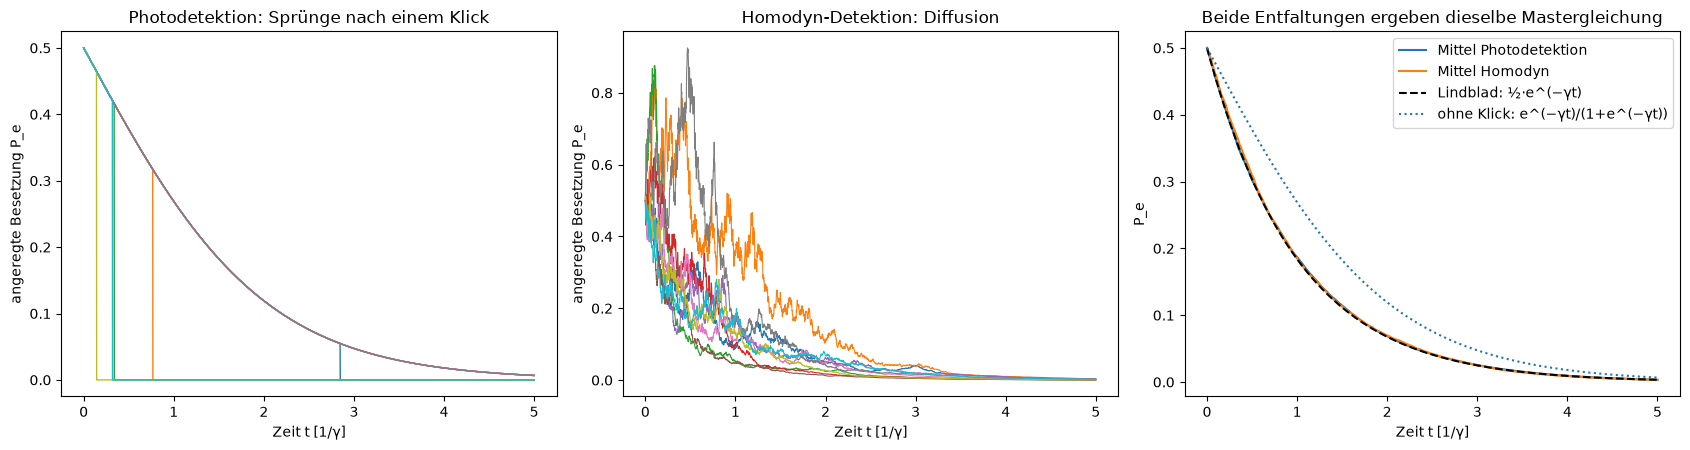

In [9]:
gamma, dt, T, n_traj = 1.0, 0.002, 5.0, 2000
sm = np.array([[0, 1], [0, 0]], dtype=complex)            # σ₋ = |0><1|: |1> (angeregt) → |0> (Grundzustand)
t = np.arange(int(T / dt) + 1) * dt
psi_start = np.array([1, 1]) / np.sqrt(2)

# Photodetektion (Monte-Carlo-Wellenfunktion): Klick mit Wahrscheinlichkeit γ·dt·P_e, dann ψ → |0>;
# ohne Klick ψ → (I − ½γ dt σ₊σ₋)ψ, normiert: Das Ausbleiben des Klicks verschiebt den Zustand Richtung |0>
psi = np.repeat(psi_start[None], n_traj, axis=0).astype(complex)
Pe_sprung = np.empty((len(t), n_traj)); Pe_sprung[0] = 0.5
for k in range(1, len(t)):
    klick = rng.random(n_traj) < gamma * dt * np.abs(psi[:, 1]) ** 2
    psi[:, 1] *= 1 - 0.5 * gamma * dt
    psi[klick] = [1, 0]
    psi /= np.linalg.norm(psi, axis=1, keepdims=True)
    Pe_sprung[k] = np.abs(psi[:, 1]) ** 2

# Homodyn-Detektion: diffusive stochastische Mastergleichung mit L = √γ σ₋
rho = np.repeat(dm(psi_start)[None], n_traj, axis=0)
Pe_homodyn = np.empty((len(t), n_traj)); Pe_homodyn[0] = 0.5
for k in range(1, len(t)):
    rho, _ = sme_step(rho, 0 * I2, np.sqrt(gamma) * sm, dt)
    Pe_homodyn[k] = rho[:, 1, 1].real

print(f"Anteil der Läufe mit Klick bis t = {T:g}/γ: {np.mean(Pe_sprung[-1] < 1e-9):.3f} "
      f"(erwartet ½(1 − e^(−γT)) = {0.5 * (1 - np.exp(-gamma * T)):.3f})")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for j in range(10):
    axes[0].plot(t, Pe_sprung[:, j], lw=1)
    axes[1].plot(t, Pe_homodyn[:, j], lw=0.8)
axes[0].set_title("Photodetektion: Sprünge nach einem Klick")
axes[1].set_title("Homodyn-Detektion: Diffusion")
for ax in axes[:2]:
    ax.set_xlabel("Zeit t [1/γ]"); ax.set_ylabel("angeregte Besetzung P_e")
axes[2].plot(t, Pe_sprung.mean(axis=1), label="Mittel Photodetektion")
axes[2].plot(t, Pe_homodyn.mean(axis=1), label="Mittel Homodyn")
axes[2].plot(t, 0.5 * np.exp(-gamma * t), "k--", label="Lindblad: ½·e^(−γt)")
axes[2].plot(t, np.exp(-gamma * t) / (1 + np.exp(-gamma * t)), ":", color="tab:blue", label="ohne Klick: e^(−γt)/(1+e^(−γt))")
axes[2].set_xlabel("Zeit t [1/γ]"); axes[2].set_ylabel("P_e")
axes[2].set_title("Beide Entfaltungen ergeben dieselbe Mastergleichung")
axes[2].legend()
plt.tight_layout()
plt.show()

* **Links (Photodetektion):** Jede Trajektorie fällt langsam, solange kein Klick kommt, und springt beim Klick auf $P_e = 0$. Auch das Ausbleiben eines Klicks ist Information: Nach $e^{-\gamma t}/(1 + e^{-\gamma t})$ wird es wahrscheinlicher, dass das Qubit schon unten war.
* **Mitte (Homodyn):** Dieselbe Mastergleichung, aber gemessen wird eine Feldquadratur; die Trajektorien diffundieren stetig nach unten, ohne Sprünge.
* **Rechts:** Beide Mittelwerte liegen auf der Lindblad-Lösung $\tfrac12e^{-\gamma t}$; die gepunktete Linie ist der Verlauf ohne Klick. Die **Ausgabe** nennt 48,8 % der Läufe mit Klick bis $t = 5/\gamma$, erwartet $\tfrac12(1 - e^{-5}) = 49{,}7$ %: Nur die halbe Population war angeregt.

##### *9. Quanten-Zeno-Effekt*

Wie wahrscheinlich bleibt ein angetriebenes Qubit bei $N$ projektiven Messungen in $\vert0\rangle$, und wie verlangsamt eine kontinuierliche Messung der Stärke $\kappa$ den Übergang? Vorher vorhersagen: Was zeigt eine einzelne Trajektorie bei starker Messung?

Links: Ein Antrieb $H = \tfrac\Omega2\sigma_x$ würde $\vert0\rangle$ in der Zeit $\pi/\Omega$ nach $\vert1\rangle$ drehen; dazwischen wird $N$-mal projektiv gemessen (Formel und 4000 Läufe). Mitte: kontinuierliche Messung mit $\kappa = 0$, $1$, $4$ und $16\,\Omega$ (Lindblad-Gleichung). Rechts: eine einzelne Trajektorie bei $\kappa = 16\,\Omega$ bis $t = 300/\Omega$ (Theorie, Abschnitt 7).

**Hintergrund & Fachbegriffe:**
- **Quanten-Zeno-Effekt:** Die Wahrscheinlichkeit, einen Zustand zu verlassen, wächst anfangs quadratisch in der Zeit; jede Messung setzt diese Uhr zurück. Mit $\ln\cos x\approx-x^2/2$ ist $\cos^{2N}(\pi/2N)\approx e^{-\pi^2/4N}\to1$.
- **Übergangsrate bei starker Messung:** Für $\kappa\gg\Omega$ folgt die Kohärenz der Besetzung sofort, und $z$ zerfällt mit der Rate $\Omega^2/2\kappa$: je stärker die Messung, desto langsamer.
- **Telegraphensignal:** ein Signal, das zufällig zwischen zwei Werten springt; so sieht eine einzelne Trajektorie bei starker Messung aus.
- **QND-Messung:** misst eine Observable, die mit $H$ vertauscht; dann friert die Messung nichts ein, sondern liefert immer wieder dasselbe Ergebnis (Variation 6).

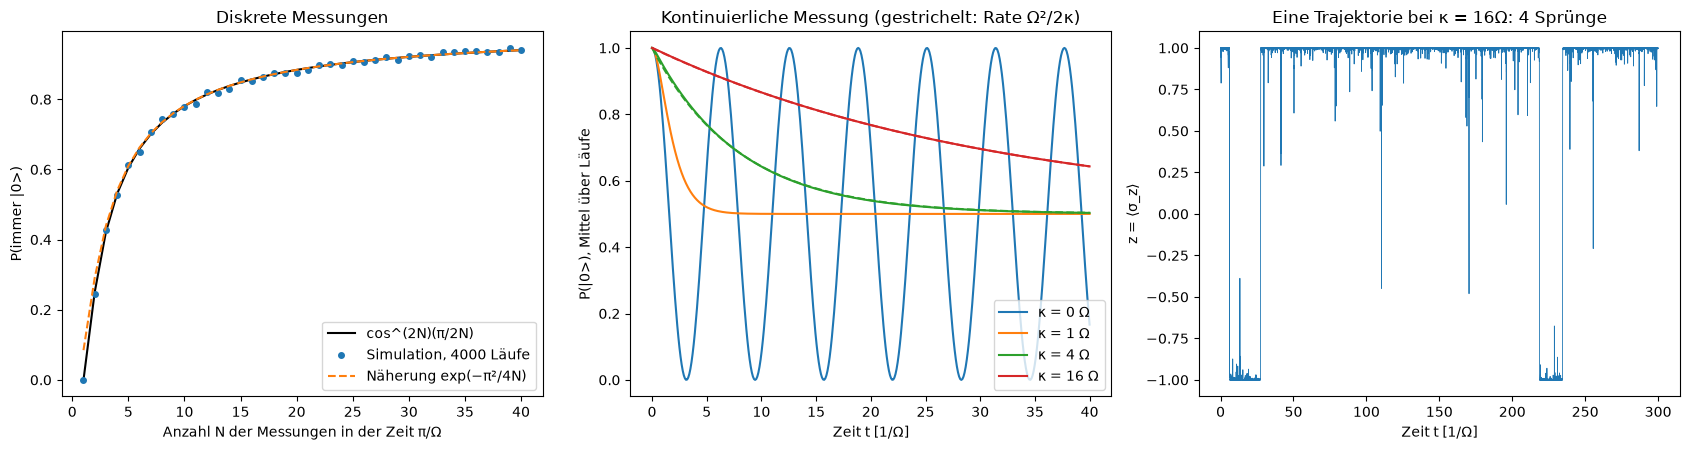

Sprünge in t = 300/Ω: 4; erwartet im Mittel 300·Ω²/(4κ) = 4.7 (Sprungrate in jede Richtung Ω²/4κ, Anzahl Poisson-verteilt)


In [10]:
Omega = 1.0
U_rabi = lambda tau: expm(-1j * Omega * tau / 2 * X)

# (a) N projektive Messungen von σ_z während der Zeit T = π/Ω (ohne Messung: vollständige Umkehr nach |1>)
T = np.pi / Omega
N_werte = np.arange(1, 41)
p_sim = []
for N in N_werte:
    p0 = abs((U_rabi(T / N) @ [1, 0])[0]) ** 2          # pro Intervall: Wahrscheinlichkeit, in |0> zu bleiben
    p_sim.append(np.mean(np.all(rng.random((4000, N)) < p0, axis=1)))   # alle N Messungen ergeben |0>
p_formel = np.cos(np.pi / (2 * N_werte)) ** (2 * N_werte)

# (b) kontinuierliche Messung: Lindblad-Gleichung mit H = (Ω/2)σ_x und L = √κ σ_z
t = np.linspace(0, 40, 400)
kurven = {}
for kappa in [0.0, 1.0, 4.0, 16.0]:
    Lv = liouvillian(Omega / 2 * X, [np.sqrt(kappa) * Z])
    rho0 = dm([1, 0]).flatten(order="F")
    kurven[kappa] = [np.real((expm(Lv * tt) @ rho0).reshape(2, 2, order="F")[0, 0]) for tt in t]

# (c) eine Trajektorie bei starker Messung, κ = 16Ω
kappa, dt = 16.0, 0.001
t_traj = np.arange(int(300 / dt) + 1) * dt
rho = dm([1, 0])[None]
z_traj = np.empty(len(t_traj)); z_traj[0] = 1
for k in range(1, len(t_traj)):
    rho, _ = sme_step(rho, Omega / 2 * X, np.sqrt(kappa) * Z, dt)
    z_traj[k] = np.real(rho[0, 0, 0] - rho[0, 1, 1])
# Sprünge mit Hysterese zählen: von z > 0.9 nach z < −0.9 oder umgekehrt (kurze Ausreißer zählen nicht)
spruenge, seite = 0, 1
for zz in z_traj:
    if seite * zz < -0.9:
        spruenge, seite = spruenge + 1, -seite

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(N_werte, p_formel, "k-", label="cos^(2N)(π/2N)")
axes[0].plot(N_werte, p_sim, "o", ms=4, label="Simulation, 4000 Läufe")
axes[0].plot(N_werte, np.exp(-np.pi ** 2 / (4 * N_werte)), "--", label="Näherung exp(−π²/4N)")
axes[0].set_xlabel("Anzahl N der Messungen in der Zeit π/Ω"); axes[0].set_ylabel("P(immer |0>)")
axes[0].set_title("Diskrete Messungen"); axes[0].legend()
for kappa, kurve in kurven.items():
    linie, = axes[1].plot(t, kurve, label=f"κ = {kappa:g} Ω")
    if kappa >= 4:
        axes[1].plot(t, 0.5 * (1 + np.exp(-Omega ** 2 * t / (2 * kappa))), "--", color=linie.get_color())
axes[1].set_xlabel("Zeit t [1/Ω]"); axes[1].set_ylabel("P(|0>), Mittel über Läufe")
axes[1].set_title("Kontinuierliche Messung (gestrichelt: Rate Ω²/2κ)"); axes[1].legend()
axes[2].plot(t_traj, z_traj, lw=0.6)
axes[2].set_xlabel("Zeit t [1/Ω]"); axes[2].set_ylabel("z = ⟨σ_z⟩")
axes[2].set_title(f"Eine Trajektorie bei κ = 16Ω: {spruenge} Sprünge")
plt.tight_layout()
plt.show()
print(f"Sprünge in t = 300/Ω: {spruenge}; erwartet im Mittel 300·Ω²/(4κ) = {300 * Omega ** 2 / (4 * 16):.1f} "
      "(Sprungrate in jede Richtung Ω²/4κ, Anzahl Poisson-verteilt)")

* **Links:** die Wahrscheinlichkeit, bei allen $N$ Messungen $\vert0\rangle$ zu finden, gegen $N$. Ohne Zwischenmessung ($N = 1$) ist sie 0, das Qubit wird vollständig gedreht; bei $N = 40$ ist sie 0,94. Simulation (Punkte), Formel $\cos^{2N}(\pi/2N)$ und Näherung $e^{-\pi^2/4N}$ stimmen überein.
* **Mitte:** die Besetzung $P(\vert0\rangle)$ bei kontinuierlicher Messung. Ohne Messung ($\kappa = 0$) schwingt sie zwischen 1 und 0. Bei $\kappa = \Omega$ ist die Schwingung schnell weggedämpft, und $P$ geht in wenigen $1/\Omega$ auf $\tfrac12$. Darüber beginnt der Zeno-Bereich: Bei $4\Omega$ und $16\Omega$ wird der Zerfall immer langsamer, mit der Rate $\Omega^2/2\kappa$ (gestrichelt, deckt sich mit der Kurve).
* **Rechts:** eine einzelne Trajektorie bei $\kappa = 16\Omega$ sitzt fast immer bei $\pm1$ und springt selten, wie ein Telegraphensignal. Die **Ausgabe** zählt 4 Sprünge in $t = 300/\Omega$, erwartet im Mittel 4,7 (Poisson-verteilt).

##### *10. Feedback: den Zufall des Kollapses beseitigen*

Kann man mit dem Messsignal selbst erreichen, dass jeder Lauf bei $z = +1$ endet? Kontinuierliche Messung von $\sigma_z$ mit $\kappa = 1$, Start in $\vert{+x}\rangle$ ($z_0 = 0$), Rückkopplung $H_\text{fb} = \tfrac u2\sigma_y$ mit $u = -\lambda\langle\sigma_x\rangle_t$. Vorher vorhersagen: Welcher Anteil endet ohne Rückkopplung bei $+1$, welcher bei $\lambda = 2\kappa$?

400 Läufe pro Rückkopplungsstärke $\lambda$ von 0 bis $8\kappa$ laufen bis $t = 12/\kappa$. Links: Trajektorien ohne Rückkopplung und mit $\lambda = 6\kappa$, rechts: der Anteil der Läufe, die bei $z = +1$ enden, gegen $\lambda$, mit der Kurve aus der Theorie (Abschnitt 8).

**Hintergrund & Fachbegriffe:**
- **Quantenfilter:** die stochastische Mastergleichung, mit dem gemessenen Signal gefüttert; sie liefert in jedem Moment den Zustand, den das Gerät kennt.
- **Messbasierte Rückkopplung:** Der Steuer-Hamilton-Operator hängt vom aktuellen Filterzustand ab, hier $u = -\lambda\langle\sigma_x\rangle_t$; er dreht den Zustand in jedem Moment Richtung $+z$, um so stärker, je weiter er von den Polen entfernt ist.
- **Warum die Schwelle bei $4\kappa$ liegt:** Mit Rückkopplung gilt $dz = (1 - z^2)(\lambda\,dt + 2\sqrt\kappa\,dW)$. In der Variablen $w = \operatorname{artanh}z$ ist die Drift nahe $z = -1$ gleich $\lambda - 4\kappa$: Darunter kann ein Lauf bei $-1$ hängen bleiben, darüber wird jeder weggetrieben und endet bei $+1$.
- **Skalenfunktion:** gibt für einen Diffusionsprozess die Wahrscheinlichkeit, zuerst den einen oder den anderen Rand zu erreichen; daraus die Kurve rechts.

λ = 0κ: Anteil bei +1 = 0.512
λ = 0.5κ: Anteil bei +1 = 0.593
λ = 1κ: Anteil bei +1 = 0.667
λ = 2κ: Anteil bei +1 = 0.835
λ = 3κ: Anteil bei +1 = 0.927
λ = 4κ: Anteil bei +1 = 0.988
λ = 6κ: Anteil bei +1 = 1.000
λ = 8κ: Anteil bei +1 = 1.000


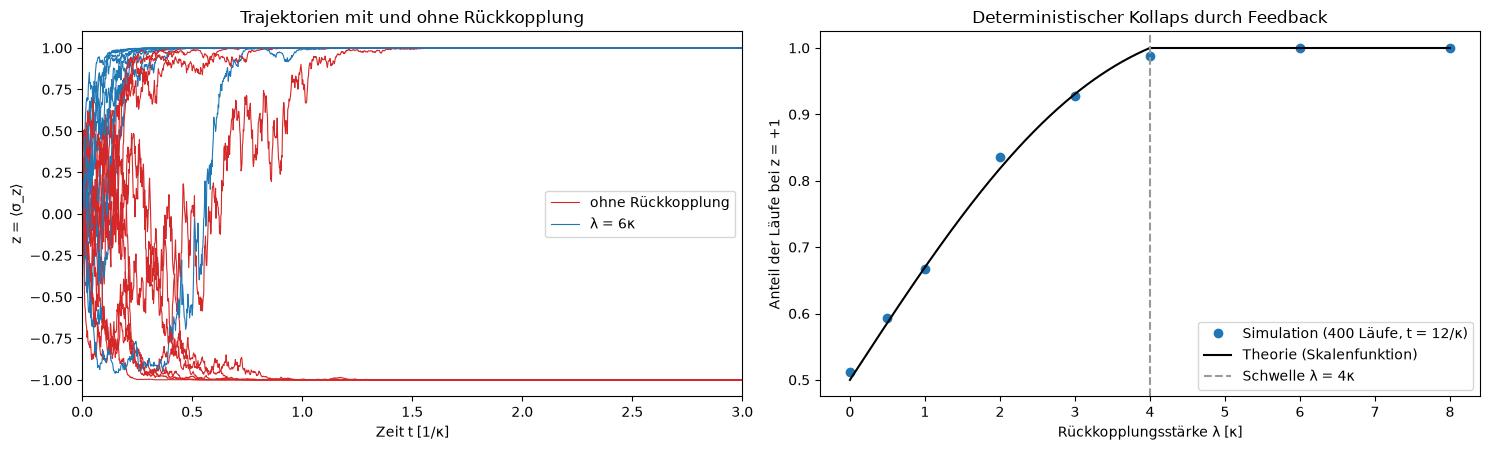

In [11]:
kappa, dt, T, n_traj = 1.0, 0.002, 12.0, 400
lambdas = np.array([0, 0.5, 1, 2, 3, 4, 6, 8])                 # in Einheiten von κ
lam = np.repeat(lambdas, n_traj)                               # alle Werte in einem Durchlauf
rho = np.repeat(dm([1, 1])[None], len(lam), axis=0)
L = np.sqrt(kappa) * Z
schritte = int(T / dt)
z_spur = np.empty((schritte + 1, len(lam))); z_spur[0] = 0
for k in range(1, schritte + 1):
    x = 2 * np.real(rho[:, 0, 1])                              # Schätzung ⟨σ_x⟩ aus dem Quantenfilter
    H = 0.5 * (-lam * x)[:, None, None] * Y                    # H_fb = (u/2) σ_y mit u = −λ⟨σ_x⟩
    rho, _ = sme_step(rho, H, L, dt)
    z_spur[k] = np.real(rho[:, 0, 0] - rho[:, 1, 1])
anteil = (z_spur[-1] > 0).reshape(len(lambdas), n_traj).mean(axis=1)

a = np.linspace(0, 0.999, 300)
theorie = 1 - betainc(1 + a, 1 - a, 0.5)                       # Skalenfunktion (Experiment 10, Fachbegriffe)
for l, p in zip(lambdas, anteil):
    print(f"λ = {l:g}κ: Anteil bei +1 = {p:.3f}")

t = np.arange(schritte + 1) * dt
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for j in range(12):
    axes[0].plot(t, z_spur[:, j], color="tab:red", lw=0.8, label="ohne Rückkopplung" if j == 0 else None)
    axes[0].plot(t, z_spur[:, 6 * n_traj + j], color="tab:blue", lw=0.8, label="λ = 6κ" if j == 0 else None)
axes[0].set_xlim(0, 3)
axes[0].set_xlabel("Zeit t [1/κ]"); axes[0].set_ylabel("z = ⟨σ_z⟩")
axes[0].set_title("Trajektorien mit und ohne Rückkopplung"); axes[0].legend()
axes[1].plot(lambdas, anteil, "o", label=f"Simulation ({n_traj} Läufe, t = {T:g}/κ)")
axes[1].plot(4 * a, theorie, "k-", label="Theorie (Skalenfunktion)")
axes[1].plot([4, 8], [1, 1], "k-")
axes[1].axvline(4, color="0.6", ls="--", label="Schwelle λ = 4κ")
axes[1].set_xlabel("Rückkopplungsstärke λ [κ]"); axes[1].set_ylabel("Anteil der Läufe bei z = +1")
axes[1].set_title("Deterministischer Kollaps durch Feedback"); axes[1].legend()
plt.tight_layout()
plt.show()

* **Links:** Trajektorien ohne Rückkopplung (rot) enden zufällig bei $+1$ oder $-1$; mit $\lambda = 6\kappa$ (blau) laufen alle nach $+1$.
* **Rechts:** der Anteil der Läufe bei $+1$ gegen $\lambda$; die Simulation (Punkte) folgt der Theoriekurve aus der Skalenfunktion, die an der Schwelle $\lambda = 4\kappa$ (gestrichelt) 1 erreicht.
* Die **Ausgabe:** ohne Rückkopplung 0,512 (Born: 0,5), bei $\lambda = 2\kappa$ 0,835, bei $4\kappa$ 0,988 (die Läufe nahe $-1$ brauchen an der Schwelle länger als $t = 12/\kappa$), ab $6\kappa$ alle 400. Der Zufall des Kollapses lässt sich mit dem Messsignal selbst beseitigen.

##### *11. Zustandstomographie: lineare Inversion gegen Maximum-Likelihood*

Zwei Qubits im Bell-Zustand $\vert\Phi^+\rangle$ mit 5 % Depolarisation, $N$ Messungen in jeder der 9 Pauli-Basen. Wie schnell fällt der Spurabstand zum wahren Zustand, und wie oft liefert die lineare Inversion einen unphysikalischen Zustand mit negativem Eigenwert? Vorher die Steigung im doppelt-logarithmischen Plot vorhersagen.

Für $N$ von 10 bis 10 000 Messungen pro Pauli-Basis wird der Zustand 20-mal geschätzt, mit linearer Inversion und mit Maximum-Likelihood (Hradil-Iteration), und der Spurabstand zum wahren Zustand gemittelt. Gezählt wird außerdem, wie oft die lineare Inversion einen negativen Eigenwert liefert (Theorie, Abschnitt 9).

**Hintergrund & Fachbegriffe:**
- **Pauli-Basen:** Für zwei Qubits misst man in den 9 Produktbasen $\{X, Y, Z\}^{\otimes2}$ und schätzt daraus alle 15 nichttrivialen Pauli-Erwartungswerte.
- **Lineare Inversion:** $\hat\rho = \tfrac14\sum_P\widehat{\langle P\rangle}P$, weil die Pauli-Strings orthogonal sind, $\mathrm{Tr}(PQ) = 4\delta_{PQ}$. Jeder Schätzwert hat die Varianz $(1 - \langle P\rangle^2)/N$, also fällt der Fehler wie $1/\sqrt N$.
- **Maximum-Likelihood:** der physikalische Zustand (positiv, Spur 1), unter dem die beobachteten Häufigkeiten am wahrscheinlichsten sind.
- **Spurabstand:** $\tfrac12\Vert\hat\rho - \rho\Vert_1$, die größte Differenz der Wahrscheinlichkeiten, die eine Messung zwischen den beiden Zuständen sehen kann.
- **Depolarisation 5 %:** $\rho = 0{,}95\,\vert\Phi^+\rangle\langle\Phi^+\vert + 0{,}05\,I/4$; der Zustand ist fast rein: ein Eigenwert 0,9625, drei Eigenwerte 0,0125.

N =    10: Spurabstand LI 0.3744, MLE 0.1693, LI unphysikalisch in 20/20 Fällen
N =    30: Spurabstand LI 0.2236, MLE 0.1263, LI unphysikalisch in 20/20 Fällen
N =   100: Spurabstand LI 0.1167, MLE 0.0751, LI unphysikalisch in 20/20 Fällen
N =   300: Spurabstand LI 0.0742, MLE 0.0568, LI unphysikalisch in 20/20 Fällen
N =  1000: Spurabstand LI 0.0359, MLE 0.0281, LI unphysikalisch in 17/20 Fällen
N =  3000: Spurabstand LI 0.0247, MLE 0.0222, LI unphysikalisch in 8/20 Fällen
N = 10000: Spurabstand LI 0.0116, MLE 0.0111, LI unphysikalisch in 1/20 Fällen


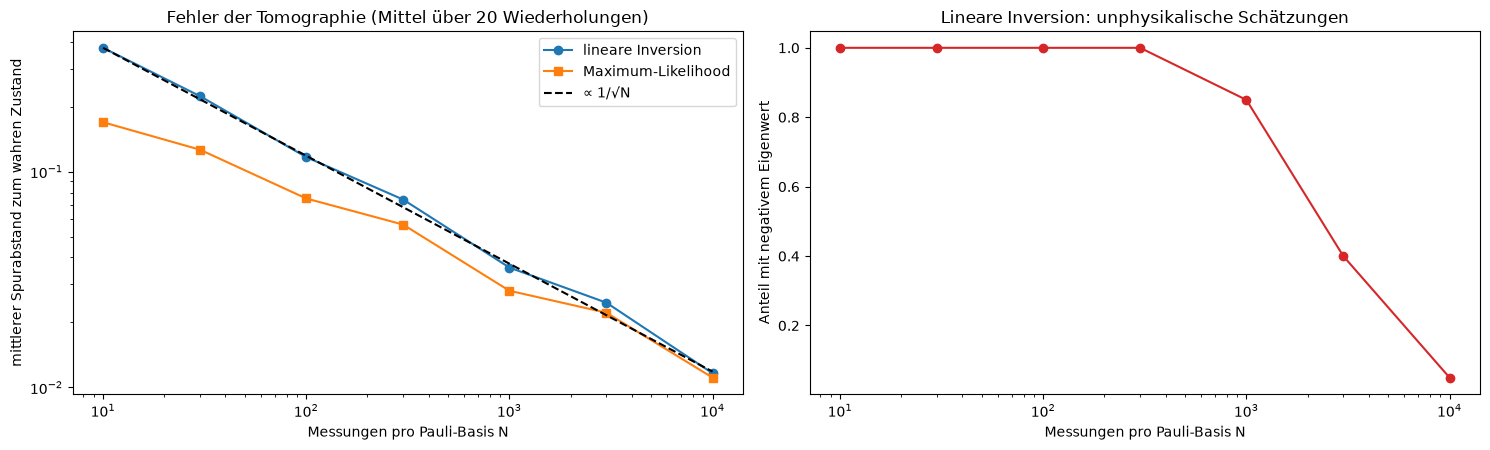

In [12]:
bell = np.array([1, 0, 0, 1]) / np.sqrt(2)
rho_wahr = 0.95 * dm(bell) + 0.05 * np.eye(4) / 4

basen = list(itertools.product("XYZ", repeat=2))              # 9 Einstellungen
ergebnisse = list(itertools.product([1, -1], repeat=2))        # 4 Ergebnisse je Einstellung
proj = np.array([[np.kron((I2 + s1 * PAULI[a]) / 2, (I2 + s2 * PAULI[c]) / 2) for s1, s2 in ergebnisse]
                 for a, c in basen])                           # Form (9, 4, 4, 4)


def messdaten(rho, N):
    """N Messungen pro Einstellung; Häufigkeiten f[Einstellung, Ergebnis]."""
    p = np.clip(np.real(np.einsum("soij,ji->so", proj, rho)), 0, None)
    return np.array([rng.multinomial(N, ps / ps.sum()) for ps in p]) / N


def lineare_inversion(f):
    """ρ = ¼ Σ_P <P> P; jeder Erwartungswert aus allen Einstellungen, die zu P passen (I passt zu jeder Basis)."""
    rho = np.zeros((4, 4), dtype=complex)
    for P1, P2 in itertools.product("IXYZ", repeat=2):
        werte = []
        for s, (a, c) in enumerate(basen):
            if P1 in ("I", a) and P2 in ("I", c):
                vorzeichen = [(s1 if P1 != "I" else 1) * (s2 if P2 != "I" else 1) for s1, s2 in ergebnisse]
                werte.append(f[s] @ vorzeichen)
        rho += np.mean(werte) * np.kron(PAULI[P1], PAULI[P2]) / 4
    return rho


def mle(f, schritte=400):
    """Maximum-Likelihood mit der RρR-Iteration von Hradil."""
    rho = np.eye(4, dtype=complex) / 4
    for _ in range(schritte):
        p = np.real(np.einsum("soij,ji->so", proj, rho))
        R = np.einsum("so,soij->ij", f / np.maximum(p, 1e-12), proj)
        rho = R @ rho @ R
        rho /= np.trace(rho).real
    return rho


N_werte = [10, 30, 100, 300, 1000, 3000, 10000]
wdh = 20
fehler_li, fehler_mle, unphysikalisch = [], [], []
for N in N_werte:
    fl, fm, neg = [], [], 0
    for _ in range(wdh):
        f = messdaten(rho_wahr, N)
        r_li = lineare_inversion(f)
        fl.append(trace_distance(r_li, rho_wahr))
        fm.append(trace_distance(mle(f), rho_wahr))
        neg += np.linalg.eigvalsh(r_li).min() < 0
    fehler_li.append(np.mean(fl)); fehler_mle.append(np.mean(fm)); unphysikalisch.append(neg / wdh)
    print(f"N = {N:5d}: Spurabstand LI {np.mean(fl):.4f}, MLE {np.mean(fm):.4f}, LI unphysikalisch in {neg}/{wdh} Fällen")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].loglog(N_werte, fehler_li, "o-", label="lineare Inversion")
axes[0].loglog(N_werte, fehler_mle, "s-", label="Maximum-Likelihood")
axes[0].loglog(N_werte, fehler_li[0] * np.sqrt(N_werte[0] / np.array(N_werte)), "k--", label="∝ 1/√N")
axes[0].set_xlabel("Messungen pro Pauli-Basis N"); axes[0].set_ylabel("mittlerer Spurabstand zum wahren Zustand")
axes[0].set_title(f"Fehler der Tomographie (Mittel über {wdh} Wiederholungen)"); axes[0].legend()
axes[1].semilogx(N_werte, unphysikalisch, "o-", color="tab:red")
axes[1].set_xlabel("Messungen pro Pauli-Basis N"); axes[1].set_ylabel("Anteil mit negativem Eigenwert")
axes[1].set_title("Lineare Inversion: unphysikalische Schätzungen")
plt.tight_layout()
plt.show()

* **Links:** der mittlere Spurabstand zum wahren Zustand gegen $N$, doppelt logarithmisch. Beide Schätzer folgen der Steigung $-\tfrac12$ ($\propto1/\sqrt N$, gestrichelt); die lineare Inversion fällt von 0,37 bei $N = 10$ auf 0,012 bei $N = 10^4$. Maximum-Likelihood ist bei kleinem $N$ bis zu 2,2-mal genauer (0,17 gegen 0,37), bei großem $N$ gleich gut.
* **Rechts:** der Anteil der linearen Schätzungen mit negativem Eigenwert. Bis $N = 300$ sind alle 20 unphysikalisch, bei $N = 3000$ noch 8, bei $N = 10^4$ einer.
* Grund: Der wahre Zustand ist fast rein, drei seiner Eigenwerte sind nur 0,0125. Schon kleines Rauschen schiebt sie unter null, bis der Fehler kleiner wird als diese Eigenwerte (0,0125). MLE sucht nur unter physikalischen Zuständen und kann das nicht.

##### *12. Prozesstomographie der Amplitudendämpfung*

Lässt sich ein unbekannter Kanal aus vier Eingangszuständen und Pauli-Messungen der Ausgänge rekonstruieren, und was passiert, wenn Präparation und Auslese selbst fehlerhaft sind? Kanal: Amplitudendämpfung mit $\gamma = 0.3$. Vorher die Pauli-Transfermatrix aus den Kraus-Operatoren ausrechnen.

Vier Eingangszustände $\vert0\rangle$, $\vert1\rangle$, $\vert{+}\rangle$, $\vert{+i}\rangle$ laufen durch den Kanal, ihre Ausgänge werden mit je 10 000 Messungen pro Pauli-Basis tomographiert, und aus der Linearität entsteht die Pauli-Transfermatrix. Einmal mit idealer Präparation und Auslese, einmal mit 4 % Präparationsfehler und 3 % Auslesefehler (Theorie, Abschnitt 9).

**Hintergrund & Fachbegriffe:**
- **Amplitudendämpfung:** der Kanal mit den Kraus-Operatoren $K_0 = \mathrm{diag}(1, \sqrt{1-\gamma})$ und $K_1 = \sqrt\gamma\,\vert0\rangle\langle1\vert$; $\vert1\rangle$ zerfällt mit Wahrscheinlichkeit $\gamma$ nach $\vert0\rangle$.
- **Pauli-Transfermatrix (PTM):** $R_{ij} = \tfrac12\mathrm{Tr}(P_i\,\mathcal E(P_j))$; sie zeigt, wie der Kanal die Bloch-Komponenten abbildet. Für die Amplitudendämpfung: $x$ und $y$ schrumpfen um $\sqrt{1-\gamma} = 0{,}837$, $z$ um $1-\gamma = 0{,}7$, und $z$ wird um $\gamma = 0{,}3$ verschoben.
- **SPAM-Fehler:** Fehler in Präparation (state preparation) und Auslese (measurement); Tomographie kann sie nicht vom Kanal trennen.

wahre PTM:
 [[1.    0.    0.    0.   ]
 [0.    0.837 0.    0.   ]
 [0.    0.    0.837 0.   ]
 [0.3   0.    0.    0.7  ]]
größte Abweichung: ohne SPAM 0.017, mit SPAM-Fehlern 0.094


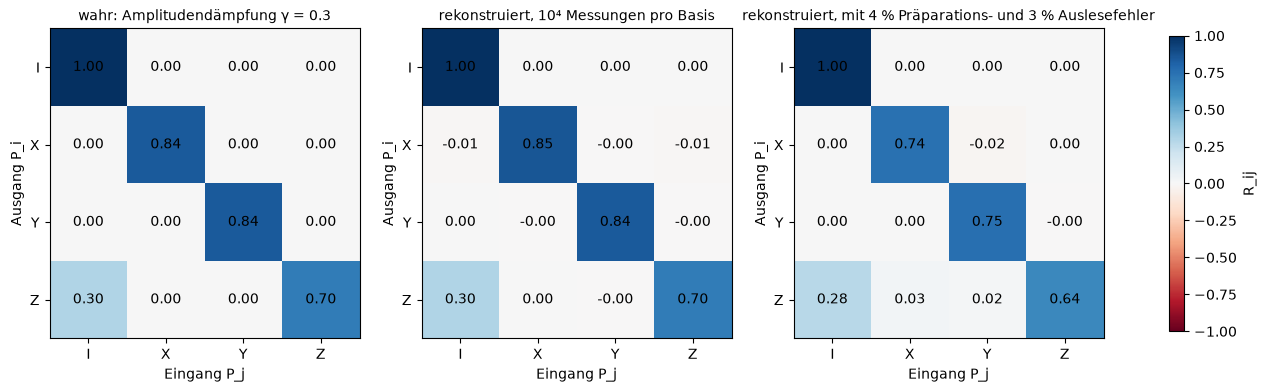

In [13]:
gamma = 0.3
K_ad = [np.array([[1, 0], [0, np.sqrt(1 - gamma)]], dtype=complex), np.array([[0, np.sqrt(gamma)], [0, 0]], dtype=complex)]
kanal = lambda rho, K: sum(k @ rho @ k.conj().T for k in K)
paulis = [I2, X, Y, Z]


def ptm(E):
    """Pauli-Transfermatrix R_ij = ½ Tr(P_i E(P_j)) eines linearen Qubit-Kanals E."""
    return np.array([[0.5 * np.trace(Pi @ E(Pj)).real for Pj in paulis] for Pi in paulis])


def qubit_tomographie(rho, N, flip=0.0):
    """Bloch-Vektor aus je N Messungen in X, Y, Z; flip = Wahrscheinlichkeit, ein Ergebnis falsch auszulesen."""
    r = []
    for P in (X, Y, Z):
        p_plus = np.clip(np.trace(rho @ (I2 + P) / 2).real, 0, 1)
        p_plus = (1 - flip) * p_plus + flip * (1 - p_plus)
        r.append(2 * rng.binomial(N, p_plus) / N - 1)
    return from_bloch(r)


def prozesstomographie(E, N, prep_fehler=0.0, flip=0.0):
    """Eingänge |0>, |1>, |+>, |+i> (bei Präparationsfehler zum Teil depolarisiert); Linearität ergibt E(P_j)."""
    eingang = {k: (1 - prep_fehler) * dm(v) + prep_fehler * I2 / 2
               for k, v in {"0": [1, 0], "1": [0, 1], "+": [1, 1], "+i": [1, 1j]}.items()}
    aus = {k: qubit_tomographie(E(r), N, flip) for k, r in eingang.items()}
    bild = {"I": aus["0"] + aus["1"], "Z": aus["0"] - aus["1"]}
    bild["X"] = 2 * aus["+"] - bild["I"]
    bild["Y"] = 2 * aus["+i"] - bild["I"]
    return np.array([[0.5 * np.trace(Pi @ bild[j]).real for j in "IXYZ"] for Pi in paulis])


E_ad = lambda rho: kanal(rho, K_ad)
R_wahr = ptm(E_ad)
R_est = prozesstomographie(E_ad, 10_000)
R_spam = prozesstomographie(E_ad, 10_000, prep_fehler=0.04, flip=0.03)
print("wahre PTM:\n", np.round(R_wahr, 3))
print(f"größte Abweichung: ohne SPAM {np.abs(R_est - R_wahr).max():.3f}, mit SPAM-Fehlern {np.abs(R_spam - R_wahr).max():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, R, titel in [(axes[0], R_wahr, "wahr: Amplitudendämpfung γ = 0.3"),
                     (axes[1], R_est, "rekonstruiert, 10⁴ Messungen pro Basis"),
                     (axes[2], R_spam, "rekonstruiert, mit 4 % Präparations- und 3 % Auslesefehler")]:
    bild = ax.imshow(R, cmap="RdBu", vmin=-1, vmax=1)
    for i_ in range(4):
        for j_ in range(4):
            ax.text(j_, i_, f"{R[i_, j_]:.2f}", ha="center", va="center", fontsize=10)
    ax.set_xticks(range(4)); ax.set_xticklabels(list("IXYZ")); ax.set_yticks(range(4)); ax.set_yticklabels(list("IXYZ"))
    ax.set_xlabel("Eingang P_j"); ax.set_ylabel("Ausgang P_i")
    ax.set_title(titel, fontsize=10)
plt.colorbar(bild, ax=axes, shrink=0.8, label="R_ij")
plt.show()

* Die drei Bilder zeigen die Pauli-Transfermatrix als Farbtafel (Eingang $P_j$ nach rechts, Ausgang $P_i$ nach unten): den wahren Kanal, die Rekonstruktion mit idealer Präparation und Auslese und die Rekonstruktion mit SPAM-Fehlern.
* Die **Ausgabe** zeigt die wahre PTM: $x$ und $y$ schrumpfen um 0,837, $z$ um 0,7, und der Eintrag 0,3 unten links verschiebt jeden Zustand Richtung $\vert0\rangle$. Ohne SPAM weicht die Rekonstruktion um höchstens 0,017 ab, das ist das statistische Rauschen von 10 000 Messungen.
* Mit 4 % Präparations- und 3 % Auslesefehler sind es 0,094: Die Einträge für $x$ und $y$ schrumpfen von 0,84 auf 0,74 und 0,75, der für $z$ von 0,70 auf 0,64, als wäre der Kanal selbst verrauschter. Prozesstomographie schreibt SPAM-Fehler dem Kanal zu; das löst erst Randomized Benchmarking (Exp. 13) oder Gate-Set-Tomographie.

##### *13. Randomized Benchmarking*

Misst Randomized Benchmarking die mittlere Fehlerrate pro Gatter richtig, obwohl Präparation und Auslese fehlerhaft sind? Rauschen nach jedem Gatter: Depolarisation ($p = 0.004$) und Amplitudendämpfung ($\gamma = 0.006$); dazu 3 % Präparationsfehler und asymmetrische Auslesefehler. Vorher die wahre Fehlerrate aus der mittleren Fidelity des Rauschkanals ausrechnen.

Für Folgenlängen $m$ werden zufällige Clifford-Folgen mit ihrem Inversen ausgeführt, jede mit 2000 Schüssen, und die Überlebenswahrscheinlichkeit wird mit $Ap^m + B$ gefittet. Verglichen wird die daraus berechnete Fehlerrate mit der wahren aus der mittleren Fidelity des Rauschkanals (Theorie, Abschnitt 9).

**Hintergrund & Fachbegriffe:**
- **Clifford-Gruppe:** die Gatter, die Pauli-Operatoren auf Pauli-Operatoren abbilden; für ein Qubit 24 Elemente (bis auf globale Phasen).
- **Twirling:** Das Mittel von $D^\dagger\Lambda D$ über die Clifford-Gruppe (ein unitäres 2-Design) ist ein depolarisierender Kanal $\rho\mapsto p\rho + (1-p)I/d$ mit derselben mittleren Fidelity wie $\Lambda$. Die ganze Folge mittelt deshalb zu $p^m\rho + (1-p^m)I/d$.
- **Unempfindlich gegen SPAM:** Präparation und Auslese stecken nur in $A$ und $B$, die Fehlerrate $r = (d-1)(1-p)/d$ nur in $p$.
- **Mittlere Fidelity:** die über alle reinen Eingangszustände gemittelte Fidelity zwischen Ein- und Ausgang eines Kanals.

Anzahl Clifford-Gatter: 24
Fit: A = 0.433, p = 0.99200, B = 0.518
Fehlerrate pro Gatter: RB 0.00400 ± 0.00005 (Fit-Unsicherheit), wahr 0.00399


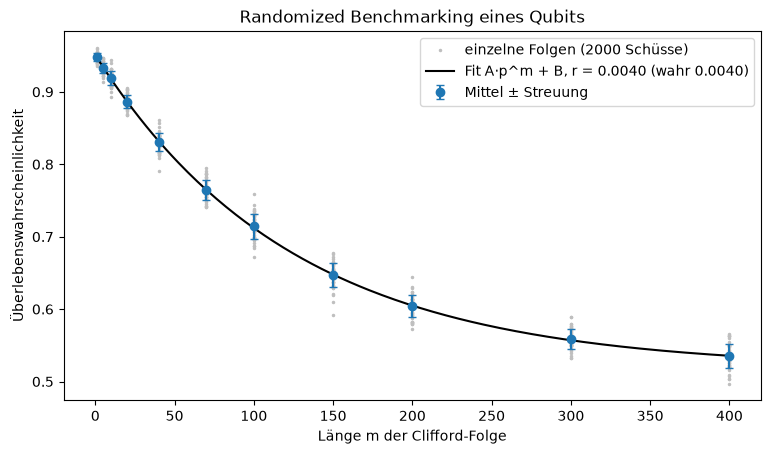

In [14]:
# Die 24 Clifford-Gatter eines Qubits: alle Produkte aus H und S, bis auf eine globale Phase
H_gate = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
S_gate = np.diag([1, 1j])


def ohne_phase(U):
    k = np.argmax(np.abs(U.ravel()) > 1e-9)                    # erstes Element ≠ 0 reell positiv machen
    return U * np.exp(-1j * np.angle(U.ravel()[k]))


cliffords, rand = [I2], [I2]
while rand:
    neu = []
    for U in rand:
        for G in (H_gate, S_gate):
            V = ohne_phase(G @ U)
            if not any(np.allclose(V, W) for W in cliffords):
                cliffords.append(V); neu.append(V)
    rand = neu
print("Anzahl Clifford-Gatter:", len(cliffords))

# Rauschen nach jedem Gatter: Depolarisation, dann Amplitudendämpfung (Kraus-Operatoren der Verkettung)
p_dep, g_ad = 0.004, 0.006
K_dep = [np.sqrt(1 - 3 * p_dep / 4) * I2] + [np.sqrt(p_dep / 4) * P for P in (X, Y, Z)]
K_amp = [np.array([[1, 0], [0, np.sqrt(1 - g_ad)]], dtype=complex), np.array([[0, np.sqrt(g_ad)], [0, 0]], dtype=complex)]
K_rausch = [a @ c for a in K_amp for c in K_dep]
F_pro = sum(abs(np.trace(K)) ** 2 for K in K_rausch) / 4      # Prozess-Fidelity
r_wahr = 1 - (2 * F_pro + 1) / 3                              # 1 − mittlere Fidelity

rho_prep = 0.97 * dm([1, 0]) + 0.03 * dm([0, 1])             # Präparationsfehler
E_auslese = np.diag([0.98, 0.05])                            # P(„0“ | |0>) = 0.98, P(„0“ | |1>) = 0.05


def ueberleben(m):
    """Überlebenswahrscheinlichkeit einer zufälligen Folge aus m Cliffords plus Inversem."""
    rho, U_ges = rho_prep, I2
    for C in [cliffords[k] for k in rng.integers(0, 24, m)] + [None]:
        G = U_ges.conj().T if C is None else C                 # zum Schluss das Inverse der ganzen Folge
        rho = kanal(G @ rho @ G.conj().T, K_rausch)
        U_ges = G @ U_ges
    return np.trace(E_auslese @ rho).real


m_werte = np.array([1, 5, 10, 20, 40, 70, 100, 150, 200, 300, 400])
folgen = 50
F = np.array([[ueberleben(m) for _ in range(folgen)] for m in m_werte])
F_schuss = rng.binomial(2000, F) / 2000                        # 2000 Wiederholungen je Folge
modell = lambda m, A, p, B: A * p ** m + B
(A, p_fit, B), kov = curve_fit(modell, np.repeat(m_werte, folgen), F_schuss.ravel(), p0=(0.5, 0.99, 0.5))
r_rb, r_unsicher = (1 - p_fit) / 2, np.sqrt(kov[1, 1]) / 2
print(f"Fit: A = {A:.3f}, p = {p_fit:.5f}, B = {B:.3f}")
print(f"Fehlerrate pro Gatter: RB {r_rb:.5f} ± {r_unsicher:.5f} (Fit-Unsicherheit), wahr {r_wahr:.5f}")

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(np.repeat(m_werte, folgen), F_schuss.ravel(), ".", color="0.75", ms=3, label="einzelne Folgen (2000 Schüsse)")
ax.errorbar(m_werte, F_schuss.mean(axis=1), F_schuss.std(axis=1), fmt="o", capsize=3, label="Mittel ± Streuung")
mm = np.linspace(0, 400, 200)
ax.plot(mm, modell(mm, A, p_fit, B), "k-", label=f"Fit A·p^m + B, r = {r_rb:.4f} (wahr {r_wahr:.4f})")
ax.set_xlabel("Länge m der Clifford-Folge"); ax.set_ylabel("Überlebenswahrscheinlichkeit")
ax.set_title("Randomized Benchmarking eines Qubits"); ax.legend()
plt.show()

* Das Bild zeigt die Überlebenswahrscheinlichkeit gegen die Folgenlänge $m$: einzelne Folgen (grau), deren Mittel mit Streuung (Punkte) und den Fit $Ap^m + B$ (schwarz). Die Kurve fällt exponentiell von etwa 0,95 bei $m = 0$ (nicht 1, wegen Präparations- und Auslesefehlern) gegen $B\approx\tfrac12$.
* Die **Ausgabe:** 24 Clifford-Gatter, Fit $A = 0{,}433$, $p = 0{,}99200$, $B = 0{,}518$. Daraus $r = (d-1)(1-p)/d = 0{,}00400\pm0{,}00005$, gegen den wahren Wert 0,00399.
* Obwohl Präparation und Auslese fehlerhaft sind ($A + B = 0{,}95$ statt 1), trifft RB die Gatterfehlerrate: Die SPAM-Fehler stecken nur in $A$ und $B$. RB sieht allerdings nur die mittlere Fidelity, nicht, ob ein Fehler kohärent ist (Variation 7).

##### *14. Classical Shadows*

Ein GHZ-Zustand aus 6 Qubits, gemessen mit zufälligen Pauli-Basen pro Qubit. Wie fällt der Fehler eines $k$-lokalen Pauli-Erwartungswerts mit der Anzahl $N$ der Schnappschüsse, und wie hängt er von $k$ ab? Vorher aus der Varianz $3^k - \langle P\rangle^2$ vorhersagen, wie viele Schnappschüsse man für $X^{\otimes6}$ braucht, um den Fehler 0.1 zu erreichen.

Für vier Pauli-Strings verschiedener Lokalität $k$ ($Z_0$, $Z_0Z_1$, $Z_0Z_1Z_2Z_3$, $X^{\otimes6}$) wird der RMS-Fehler des Schattenschätzers aus 40 Wiederholungen bei $N = 100$ bis 30 000 Schnappschüssen bestimmt und mit $\sqrt{(3^k - \langle P\rangle^2)/N}$ verglichen. Zum Schluss schätzt ein einziger Datensatz alle zwei-lokalen Pauli-Strings zugleich (Theorie, Abschnitt 9).

**Hintergrund & Fachbegriffe:**
- **GHZ-Zustand:** $(\vert0\rangle^{\otimes6} + \vert1\rangle^{\otimes6})/\sqrt2$; er hat $\langle Z_iZ_j\rangle = 1$, $\langle Z_i\rangle = 0$ und $\langle X^{\otimes6}\rangle = 1$.
- **Schnappschuss:** Für ein Qubit, gemessen in Basis $P$ mit Ergebnis $b$, ist $\hat\rho = 3\Pi_b - I$. Das Mittel über die zufällige Basis ist $\tfrac13(\rho + I)$, und $3(\cdot) - I$ macht den Schätzer erwartungstreu.
- **Varianz $3^k$:** Ein $k$-lokaler Pauli-String liefert pro Schnappschuss $\pm3^k$, wenn alle $k$ Basen passen (Wahrscheinlichkeit $3^{-k}$), sonst 0; daraus die Varianz $3^k - \langle P\rangle^2$.
- **RMS-Fehler:** die Wurzel aus dem mittleren quadratischen Fehler über die Wiederholungen.

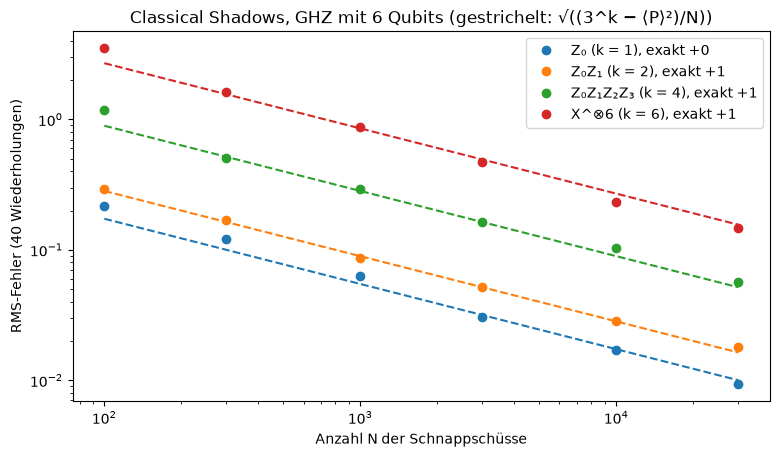

Aus 30 000 Schnappschüssen: größter Fehler über alle 135 zwei-lokalen Pauli-Strings 0.052, mittlerer 0.015


In [15]:
n = 6
ghz = np.zeros(2 ** n, dtype=complex); ghz[[0, -1]] = 1 / np.sqrt(2)
U_basis = {0: H_gate, 1: H_gate @ S_gate.conj().T, 2: I2}      # Drehung, nach der in Z gemessen wird: X, Y, Z
pauli_name = {0: "X", 1: "Y", 2: "Z"}

# Wahrscheinlichkeiten der Ergebnisse für alle 3^6 = 729 Basiseinstellungen, einmal vorberechnet
einstellungen = list(itertools.product(range(3), repeat=n))
p_einst = np.array([np.abs(functools.reduce(np.kron, [U_basis[k] for k in e]) @ ghz) ** 2 for e in einstellungen])
bits = (np.arange(2 ** n)[:, None] >> np.arange(n - 1, -1, -1)) & 1     # Bit von Qubit 0 zuerst


def schnappschuesse(N):
    """N Schnappschüsse: zufällige Basis pro Qubit (0 = X, 1 = Y, 2 = Z) und Ergebnis ±1."""
    code_ = rng.integers(0, 3 ** n, N)
    basen = np.array(einstellungen)[code_]
    ergebnis = np.empty(N, dtype=int)
    for c in np.unique(code_):
        idx = np.where(code_ == c)[0]
        ergebnis[idx] = rng.choice(2 ** n, size=len(idx), p=p_einst[c] / p_einst[c].sum())
    return basen, 1 - 2 * bits[ergebnis]


def schaetzwerte(basen, s, pauli):
    """Schätzwert pro Schnappschuss: 3^k Π s_i, falls alle Basen zu pauli passen, sonst 0."""
    w = np.ones(len(basen))
    for qb, b in pauli.items():
        w = w * 3 * (basen[:, qb] == b) * s[:, qb]
    return w


def exakt(pauli):
    P = functools.reduce(np.kron, [PAULI[pauli_name[pauli[qb]]] if qb in pauli else I2 for qb in range(n)])
    return np.real(ghz.conj() @ P @ ghz)


beobachtungen = {"Z₀ (k = 1)": {0: 2}, "Z₀Z₁ (k = 2)": {0: 2, 1: 2},
                 "Z₀Z₁Z₂Z₃ (k = 4)": {q_: 2 for q_ in range(4)}, "X^⊗6 (k = 6)": {q_: 0 for q_ in range(6)}}
N_werte = np.array([100, 300, 1000, 3000, 10000, 30000])
wdh = 40
fehler = {name: np.zeros(len(N_werte)) for name in beobachtungen}
for _ in range(wdh):
    basen, s = schnappschuesse(N_werte[-1])
    for name, pauli in beobachtungen.items():
        w = schaetzwerte(basen, s, pauli)
        fehler[name] += (np.array([w[:N].mean() for N in N_werte]) - exakt(pauli)) ** 2 / wdh

fig, ax = plt.subplots(figsize=(9, 4.8))
for name, pauli in beobachtungen.items():
    k = len(pauli)
    linie, = ax.loglog(N_werte, np.sqrt(fehler[name]), "o", label=f"{name}, exakt {exakt(pauli):+.0f}")
    ax.loglog(N_werte, np.sqrt((3 ** k - exakt(pauli) ** 2) / N_werte), "--", color=linie.get_color())
ax.set_xlabel("Anzahl N der Schnappschüsse"); ax.set_ylabel(f"RMS-Fehler ({wdh} Wiederholungen)")
ax.set_title(f"Classical Shadows, GHZ mit 6 Qubits (gestrichelt: √((3^k − ⟨P⟩²)/N))")
ax.legend()
plt.show()

# Ein einziger Datensatz für alle 135 zwei-lokalen Pauli-Observablen zugleich
basen, s = schnappschuesse(30000)
abw = [abs(schaetzwerte(basen, s, {q1: b1, q2: b2}).mean() - exakt({q1: b1, q2: b2}))
       for q1, q2 in itertools.combinations(range(n), 2) for b1 in range(3) for b2 in range(3)]
print(f"Aus 30 000 Schnappschüssen: größter Fehler über alle {len(abw)} zwei-lokalen Pauli-Strings {max(abw):.3f}, "
      f"mittlerer {np.mean(abw):.3f}")

* Das Bild zeigt den RMS-Fehler gegen die Zahl $N$ der Schnappschüsse, doppelt logarithmisch, für vier Pauli-Strings; gestrichelt jeweils $\sqrt{(3^k - \langle P\rangle^2)/N}$. Alle folgen der Steigung $-\tfrac12$, und die Höhe wächst mit der Lokalität $k$.
* $Z_0$ ($k = 1$, exakt 0) und $Z_0Z_1$ ($k = 2$, exakt $+1$) sind schon mit wenigen tausend Schnappschüssen gut bestimmt; für $X^{\otimes6}$ ($k = 6$, exakt $+1$) ist der Fehler rund 9,5-mal größer als für $Z_0Z_1$, weil nur jeder $3^6 = 729$-te Schnappschuss alle sechs Basen trifft.
* Die **Ausgabe:** Ein einziger Datensatz aus 30 000 Schnappschüssen schätzt alle 135 zwei-lokalen Pauli-Strings zugleich, mit größtem Fehler 0,052 und mittlerem 0,015. Darin liegt der Vorteil: Der Aufwand hängt von $k$ und nur logarithmisch von der Zahl der Observablen ab, nicht von der Zahl der Qubits.

#### **Ergebnis**

Beim Lauf vom 2026-10-13:

- **POVMs:** Trine und SIC sind gültige POVMs. Ihre Elemente haben Rang 1 (Eigenwerte 0 und 2/3 bzw. 0 und 1/2), sind aber keine Projektoren. Die Naimark-Unitäre (6×6 bzw. 8×8) liefert dieselben Wahrscheinlichkeiten auf vier Stellen; das SIC-POVM ist informationell vollständig.
- **Zeigermodell:** Bei $g/\sigma = 3$ trennen sich die beiden Zeigerpositionen (projektive Messung), bei $g/\sigma = 0.2$ überlappen sie fast ganz. Information $\Phi(g/\sigma)$ und verbleibende Kohärenz $e^{-g^2/2\sigma^2}$ stimmen mit Simulation und direkter Rechnung überein. Bei $g = \sigma$ rät man in 84 % der Fälle richtig und behält 61 % der Kohärenz.
- **Zwei Zustände:** Die Helstrom-Fehler stimmen mit der Formel überein ($c = 0.6$: 0.1007 simuliert, 0.1000 Formel); die naive Messung macht bei kleinem Überlapp doppelt so viele Fehler. Die eindeutige Unterscheidung irrt sich in 100 000 Läufen kein einziges Mal und sagt mit Wahrscheinlichkeit $c$ „?“.
- **Drei Zustände:** SDP und PGM geben für die Trine beide 2/3. Ab $\beta\approx90°$ erreicht die beste Messung 2/3, und mehr geht nicht: $\sum_ip_i\mathrm{Tr}(E_i\rho_i)\le\tfrac13\sum_i\mathrm{Tr}\,E_i = d/3 = 2/3$. Für drei zufällige gemischte Zustände mit ungleichen Priors liegt die PGM deutlich unter dem Optimum (0.539 gegen 0.620), aber über $P_\text{opt}^2 = 0.384$.
- **Unschärfe:** Für Zustände in der x-z-Ebene ist die Robertson-Schranke null und sagt nichts; Maassen–Uffink garantiert 1 Bit, erreicht genau an den Eigenzuständen. Die Schrödinger-Relation ist für reine Zustände eine Gleichung (Punkte auf der Diagonalen). Die gemeinsame Messbarkeit endet genau am Viertelkreis $\eta_x^2 + \eta_z^2 = 1$.
- **Weak Value:** $A_w = \cot\varepsilon = 9.97$ bei einer Postselektionsrate von 1 %. Im schwachen Grenzfall ist der Zeiger um $g\,A_w$ verschoben; ab $g/\sigma\approx0.1$ wird die Verschiebung kleiner, bei starker Kopplung liegt sie im Spektrum $[-1, 1]$. Um die Verschiebung $0.5\sigma$ bei $g = 0.05\sigma$ mit fünf Standardabweichungen zu sehen, braucht man rund $10^4$ Läufe.
- **Kontinuierliche Messung:** 69.7 % der 1000 Läufe enden bei $+1$ (Born: 70 %); nach $t = 4/\kappa$ sind alle Läufe kollabiert ($\vert z\vert>0.99$). Das Mittel von $z$ bleibt 0.4, das Mittel von $x$ fällt wie $e^{-2\kappa t}$: Die Born-Regel und die Dephasierung der Lindblad-Gleichung folgen aus derselben stochastischen Gleichung.
- **Sprünge und Diffusion:** Photodetektion und Homodyn-Detektion geben völlig verschiedene Trajektorien, im Mittel aber beide $\tfrac12e^{-\gamma t}$. Auch ohne Klick fällt $P_e$, nach $e^{-\gamma t}/(1 + e^{-\gamma t})$. Bis $t = 5/\gamma$ klicken 48.8 % der Läufe (erwartet 49.7 %).
- **Zeno:** $P(\text{immer }\vert0\rangle) = \cos^{2N}(\pi/2N)$ steigt von 0 ($N = 1$) auf 0.94 ($N = 40$). Bei kontinuierlicher Messung fällt die Übergangsrate wie $\Omega^2/2\kappa$; eine einzelne Trajektorie bei $\kappa = 16\Omega$ springt wie ein Telegraphensignal zwischen $\pm1$ (4 Sprünge in $t = 300/\Omega$, im Mittel erwartet 4.7).
- **Feedback:** Ohne Rückkopplung enden 51 % der Läufe bei $+1$, mit $\lambda = 2\kappa$ 84 %, ab $\lambda = 6\kappa$ alle 400. Die Simulation folgt der Kurve aus der Skalenfunktion; an der Schwelle $\lambda = 4\kappa$ sind es bis $t = 12/\kappa$ 98.8 %.
- **Zustandstomographie:** Der Fehler beider Schätzer fällt wie $1/\sqrt N$ (lineare Inversion: von 0.37 bei $N = 10$ auf 0.012 bei $N = 10^4$). Für den fast reinen Zustand ist die lineare Inversion bis $N = 300$ in allen 20 Wiederholungen unphysikalisch; MLE ist bei kleinem $N$ bis zu 2.2-mal genauer, bei großem $N$ gleich gut.
- **Prozesstomographie:** Die rekonstruierte Pauli-Transfermatrix der Amplitudendämpfung weicht um höchstens 0.017 ab. Mit 4 % Präparations- und 3 % Auslesefehler sind es 0.094: Die Diagonale schrumpft von 0.84 auf 0.74, als wäre der Kanal selbst verrauschter.
- **Randomized Benchmarking:** 24 Clifford-Gatter, Fit $p = 0.99200$, also $r = 0.00400\pm0.00005$ gegen den wahren Wert 0.00399, obwohl Präparation und Auslese fehlerhaft sind ($A + B = 0.95$ statt 1).
- **Classical Shadows:** Die Fehler folgen $\sqrt{(3^k - \langle P\rangle^2)/N}$; für $X^{\otimes6}$ ($k = 6$) sind sie rund 9.5-mal größer als für $Z_0Z_1$ ($k = 2$). Ein einziger Datensatz aus 30 000 Schnappschüssen schätzt alle 135 zwei-lokalen Pauli-Strings zugleich, mit größtem Fehler 0.052 und mittlerem 0.015.

#### **Variationen**

Jeweils zuerst die Vorhersage aufschreiben, dann den Code ändern.

1. **Ungleiche Priors** (Experiment 3): $p_0 = 0.8$. Wie ändert sich die Helstrom-Kurve? *(Formel: $\tfrac12(1 - \sqrt{1 - 4p_0p_1c^2})$; bei $c = 1$ bleibt der Fehler $p_1 = 0.2$, man rät immer „0“.)*
2. **SIC statt Trine** (Experiment 4): vier Tetraeder-Zustände mit gleichen Priors. Welche Erfolgswahrscheinlichkeit erreicht die beste Messung? *(Vorhersage: 1/2, und die PGM ist optimal, weil die Menge symmetrisch ist.)*
3. **Weniger orthogonal** (Experiment 6): $\varepsilon = 0.3$. Wie ändern sich $A_w$, die Postselektionsrate und die nötige Zahl der Läufe?
4. **Anderer Anfangszustand** (Experiment 7): $z_0 = -0.6$. *(Vorhersage: 20 % der Läufe enden bei +1.)*
5. **Zeno ohne Trennung der Zeitskalen** (Experiment 9): $\kappa = \Omega/2$. Warum stimmt die gestrichelte Näherung dann nicht?
6. **QND-Messung** (Experiment 9): Ersetze den Antrieb durch $H = \tfrac\Omega2\sigma_z$. Was ändert die Messung jetzt an der Dynamik?
7. **Kohärenter Fehler** (Experiment 13): Ersetze das Rauschen durch die Überrotation $e^{-i\varepsilon\sigma_z/2}$ mit $\varepsilon = 0.05$ nach jedem Gatter. *(Vorhersage: $r = \tfrac23\sin^2(\varepsilon/2)\approx4.2\cdot10^{-4}$; RB sieht nur die mittlere Fidelity, nicht dass der Fehler kohärent ist.)*
8. **Produktzustand** (Experiment 14): $\vert0\rangle^{\otimes6}$ statt GHZ. Welche Fehler ändern sich? *(Die Varianz $3^k - \langle P\rangle^2$ hängt vom Zustand nur über $\langle P\rangle$ ab.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was ist der Unterschied zwischen Messoperatoren und POVM-Elementen?</summary>

$E_m = M_m^\dagger M_m$. Das POVM bestimmt nur die Wahrscheinlichkeiten; die Messoperatoren bestimmen zusätzlich den Zustand danach. $M_m$ und $U_mM_m$ haben dasselbe POVM.
</details>

<details><summary>2. Warum kann ein Qubit-POVM vier Ergebnisse haben, eine projektive Messung aber höchstens zwei?</summary>

Projektoren auf orthogonale Unterräume von $\mathbb C^2$ gibt es höchstens zwei. POVM-Elemente müssen nur positiv sein und sich zu $I$ summieren; nach Naimark ist ein POVM mit vier Ergebnissen eine projektive Messung auf System ⊗ Ancilla mit Dimension $2\cdot4$.
</details>

<details><summary>3. Welche Formel hat die kleinste Fehlerwahrscheinlichkeit für zwei Zustände, und welche Messung erreicht sie?</summary>

$P_\text{err} = \tfrac12(1 - \Vert p_0\rho_0 - p_1\rho_1\Vert_1)$, erreicht vom Projektor auf den positiven Eigenraum von $p_0\rho_0 - p_1\rho_1$.
</details>

<details><summary>4. Was kostet eindeutige Unterscheidung zweier reiner Zustände?</summary>

Mit gleichen Priors sagt die beste Messung mit Wahrscheinlichkeit $\vert\langle\psi_0\vert\psi_1\rangle\vert$ „?“; dafür irrt sie sich nie.
</details>

<details><summary>5. Worin unterscheiden sich Präparations-Unschärfe und gemeinsame Messbarkeit?</summary>

Präparations-Unschärfe: Kein Zustand hat in $X$ und $Z$ scharfe Werte (Robertson, Maassen–Uffink). Gemeinsame Messbarkeit: Ob ein einziges POVM beide Messungen als Ränder hat; für unscharfe $\sigma_x$, $\sigma_z$ genau dann, wenn $\eta_x^2 + \eta_z^2\le1$.
</details>

<details><summary>6. Was ist ein Weak Value, und warum widerspricht ein Wert von 10 für σ_z nicht der Quantenmechanik?</summary>

$A_w = \langle\phi\vert A\vert\psi\rangle/\langle\phi\vert\psi\rangle$, die mittlere Zeigerverschiebung nach schwacher Kopplung und Postselektion. Der große Wert entsteht durch die Auswahl seltener Läufe; ohne Postselektion ist der Mittelwert $\langle A\rangle$ im Spektrum.
</details>

<details><summary>7. Wie folgt die Born-Regel aus der kontinuierlichen Messung?</summary>

$dz = 2\sqrt\kappa(1 - z^2)dW$ hat keine Drift, also bleibt der Erwartungswert $z_0$; jeder Lauf endet bei $\pm1$. Daraus $P(+1) = (1 + z_0)/2$.
</details>

<details><summary>8. Warum gibt es zu einer Lindblad-Gleichung verschiedene Trajektorien?</summary>

Die Lindblad-Gleichung beschreibt nur das Mittel. Wie der Zustand in einem einzelnen Lauf aussieht, hängt davon ab, was man misst (Photonen zählen: Sprünge; Feldquadratur: Diffusion).
</details>

<details><summary>9. Was macht den Zeno-Effekt aus, und wie groß ist die Übergangsrate bei starker kontinuierlicher Messung?</summary>

Die Wahrscheinlichkeit, einen Zustand zu verlassen, wächst anfangs quadratisch in der Zeit; häufige Messungen setzen diese Uhr immer wieder zurück. Kontinuierlich: Rate $\Omega^2/2\kappa$ für $\langle\sigma_z\rangle$.
</details>

<details><summary>10. Warum braucht MLE mehr Rechnung als lineare Inversion, und was gewinnt man?</summary>

Lineare Inversion ist eine Formel, kann aber negative Eigenwerte liefern. MLE sucht im Raum der physikalischen Zustände das Maximum der Likelihood (iterativ) und liefert immer einen gültigen Zustand.
</details>

<details><summary>11. Warum ist Randomized Benchmarking unempfindlich gegen SPAM-Fehler?</summary>

Das Mitteln über zufällige Clifford-Folgen macht aus dem Rauschen einen depolarisierenden Kanal; die Überlebenswahrscheinlichkeit ist $Ap^m + B$. Präparation und Auslese ändern nur $A$ und $B$, die Fehlerrate steckt in $p$.
</details>

<details><summary>12. Wovon hängt der Aufwand von Classical Shadows ab?</summary>

Von der Lokalität $k$ der Observablen ($3^k$) und logarithmisch von ihrer Anzahl $M$, nicht von der Gesamtzahl $n$ der Qubits.
</details>

#### **Nächste Schritte**

- **Abstände und Entropien:** Spurabstand, Fidelity, Diamantnorm und die Holevo-Schranke, die bestimmt, wie viel Information eine Messung höchstens gewinnt: Notebook [Quanteninformationstheorie und Abstandsmaße](https://github.com/deltorobarba/science/blob/main/quantum/quantuminformation.ipynb).
- **Gate-Set-Tomographie** (GST): rekonstruiert Gatter, Präparation und Auslese gemeinsam und selbstkonsistent, statt SPAM als perfekt anzunehmen.
- **Cross-Entropy-Benchmarking** (XEB): Fidelity zufälliger Schaltkreise aus den Wahrscheinlichkeiten der gemessenen Bitstrings; so wurde der Quantenvorteil von Sycamore gemessen.
- **Direct Fidelity Estimation:** Fidelity mit einem reinen Zielzustand aus wenigen zufällig gewählten Pauli-Erwartungswerten, ohne volle Tomographie.
- **Korrektur von Auslesefehlern:** Konfusionsmatrix $A_{ij} = P(\text{gelesen }i\mid\text{Zustand }j)$ messen und die gemessenen Häufigkeiten mit $A^{-1}$ korrigieren.
- **Bell-Messung und Teleportation:** eine verschränkte Messung an zwei Systemen; Prinzip der aufgeschobenen Messung (deferred measurement) und Messungen mitten im Schaltkreis.
- **Kontinuierliche Variablen:** Homodyn- und Heterodyn-Messung, Husimi-Q-Funktion als Statistik der Heterodyn-Messung.
- **Messungsinduzierte Phasenübergänge:** zufällige Schaltkreise mit Messungen; ab einer kritischen Messrate wächst die Verschränkung nicht mehr mit der Systemgröße.
- **Quantenmetrologie:** Quanten-Fisher-Information und die Cramér–Rao-Schranke als Grenze jeder Messung eines Parameters.

#### **Referenzen**

- M. A. Nielsen, I. L. Chuang: *Quantum Computation and Quantum Information*, Abschnitte 2.2.3–2.2.6 (Messung, POVM), 8.4.2 (Zustands- und Prozesstomographie), 9.2 (Spurabstand und Fidelity).
- H. M. Wiseman, G. J. Milburn: *Quantum Measurement and Control*, Cambridge 2010, Kapitel 1 (Messtheorie, Zeigermodell), 4 (Quanten-Trajektorien), 5 (Feedback).
- K. Jacobs, D. A. Steck: *A straightforward introduction to continuous quantum measurement*, Contemp. Phys. 47, 279 (2006).
- C. W. Helstrom: *Quantum Detection and Estimation Theory*, Academic Press 1976 (das Kapitel zur optimalen Entscheidung zwischen zwei Hypothesen).
- S. M. Barnett, S. Croke: *Quantum state discrimination*, Adv. Opt. Photon. 1, 238 (2009), die Abschnitte zu Minimum-Error- und eindeutiger Unterscheidung.
- H. Barnum, E. Knill: *Reversing quantum dynamics with near-optimal quantum and classical fidelity*, J. Math. Phys. 43, 2097 (2002).
- H. Maassen, J. B. M. Uffink: *Generalized entropic uncertainty relations*, Phys. Rev. Lett. 60, 1103 (1988).
- P. Busch: *Unsharp reality and joint measurements for spin observables*, Phys. Rev. D 33, 2253 (1986).
- Y. Aharonov, D. Z. Albert, L. Vaidman: *How the result of a measurement of a component of the spin of a spin-1/2 particle can turn out to be 100*, Phys. Rev. Lett. 60, 1351 (1988).
- J. Dalibard, Y. Castin, K. Mølmer: *Wave-function approach to dissipative processes in quantum optics*, Phys. Rev. Lett. 68, 580 (1992).
- P. Rouchon, J. F. Ralph: *Efficient quantum filtering for quantum feedback control*, Phys. Rev. A 91, 012118 (2015).
- B. Misra, E. C. G. Sudarshan: *The Zeno's paradox in quantum theory*, J. Math. Phys. 18, 756 (1977).
- R. van Handel, J. K. Stockton, H. Mabuchi: *Feedback control of quantum state reduction*, IEEE Trans. Autom. Control 50, 768 (2005).
- Z. Hradil: *Quantum-state estimation*, Phys. Rev. A 55, R1561 (1997).
- J. Haah, A. W. Harrow, Z. Ji, X. Wu, N. Yu: *Sample-optimal tomography of quantum states*, IEEE Trans. Inf. Theory 63, 5628 (2017).
- R. O'Donnell, J. Wright: *Efficient quantum tomography*, STOC 2016.
- E. Magesan, J. M. Gambetta, J. Emerson: *Scalable and robust randomized benchmarking of quantum processes*, Phys. Rev. Lett. 106, 180504 (2011).
- H.-Y. Huang, R. Kueng, J. Preskill: *Predicting many properties of a quantum system from very few measurements*, Nat. Phys. 16, 1050 (2020).
- S. Aaronson: *Shadow tomography of quantum states*, STOC 2018.